# Uber India Driver Earnings & Trip Settlement System
## SQL Developer Colab

**Industry:** Mobility  
**Role:** SQL Developer  
**Runtime:** Google Colab  
**Database:** SQLite  
**Main skills:** Relational design, REST API consumption, SQL analysis, transaction control, automation design, and safe engineering workflows

### Business Context
Driver Operations needs one relational control system to reconcile completed trips, driver earnings, commissions, cash collections, incentives, payout batches, and bank transfers. The SQL Developer will consume the provided internal API, validate the Dataset, design the relational model, investigate payout exceptions, and create repeatable SQL controls for weekly driver settlement.


## How to Use This Notebook

1. Open **Runtime → Run all** once.
2. Wait until you see **SETUP COMPLETE**.
3. Scroll to the large **SQL DEVELOPER WORK STARTS HERE** heading.
4. Edit only cells marked **SQL DEVELOPER WORKSPACE**.
5. Use the Expected Output and Hint immediately after each workspace.
6. Unanswered workspaces return **Needs Review** rather than a red runtime error, so the notebook remains safe to rerun.


# 1. RUN THIS SETUP ONCE - DO NOT EDIT

Everything required for this product is prepared here: Dataset, temporary internal API, JSON extraction, SQLite schema, validation helpers, and payout reconciliation controls. Do not edit setup cells.

## 1.1 Environment and Project Folder

In [69]:
from __future__ import annotations
import json, math, os, random, re, shutil, sqlite3, threading, time
from collections import defaultdict
from datetime import date, datetime, timedelta
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urlparse

import pandas as pd
import requests
from IPython.display import display, Image

try:
    from graphviz import Digraph
except Exception:
    !pip -q install graphviz
    from graphviz import Digraph

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
PROJECT_ROOT = BASE_DIR / 'uber_india_driver_settlement_sql'
if PROJECT_ROOT.exists():
    shutil.rmtree(PROJECT_ROOT)
for folder in ['data/raw','data/processed','database','logs','reports','diagrams']:
    (PROJECT_ROOT/folder).mkdir(parents=True,exist_ok=True)
SEED=20260813
print('Environment ready')
print('Project root:',PROJECT_ROOT)


Environment ready
Project root: /content/uber_india_driver_settlement_sql


## 1.2 Dataset

In [2]:
SEED=20260813
rng=random.Random(SEED)
CITIES=['Bengaluru','Mumbai','Delhi','Hyderabad','Chennai','Pune','Kolkata','Ahmedabad']
VEHICLES=['BIKE','AUTO','CAR']
COMM_RATES={'BIKE':0.16,'AUTO':0.18,'CAR':0.20}
PAYMENT_MODES=['UPI','CARD','CASH','WALLET']


drivers=[]
first_names=['Aarav','Vihaan','Aditya','Arjun','Rohan','Kabir','Ishaan','Rahul','Vikram','Karan','Neeraj','Manish','Deepak','Sanjay','Nikhil','Ankit','Ravi','Amit','Varun','Sameer']
last_names=['Sharma','Patel','Kumar','Singh','Reddy','Nair','Mehta','Gupta','Iyer','Das','Joshi','Verma']
for i in range(1,81):
    drivers.append({
        'driver_id':f'DRV{i:04d}',
        'driver_name':f'{rng.choice(first_names)} {rng.choice(last_names)} {i:02d}',
        'city':CITIES[(i-1)%len(CITIES)],
        'vehicle_type':VEHICLES[(i-1)%len(VEHICLES)],
        'join_date':(date(2023,1,1)+timedelta(days=rng.randint(0,1050))).isoformat(),
        'status':rng.choices(['ACTIVE','TEMP_HOLD'],[0.95,0.05])[0],
        'payout_cycle':'WEEKLY'
    })
commission_rules=[{'vehicle_type':v,'commission_rate':COMM_RATES[v],'cancellation_fee_share':0.50} for v in VEHICLES]

trips=[]
start=datetime(2026,7,1)
for i in range(1,1501):
    d=drivers[(i*17 + rng.randint(0,79))%80]
    ts=start+timedelta(minutes=rng.randint(0,31*24*60-1))
    status=rng.choices(['COMPLETED','CANCELLED','FAILED'],[0.88,0.08,0.04])[0]
    mode=rng.choices(PAYMENT_MODES,[0.42,0.24,0.24,0.10])[0]
    dist=round(rng.uniform(1.2,28),2)
    wait=rng.randint(0,18)
    base=round(rng.uniform(35,65),2)
    distance_charge=round(dist*rng.uniform(9,16),2)
    waiting_fee=round(max(wait-3,0)*2.0,2)
    toll=round(rng.choice([0,0,0,20,35,50,75]),2)
    cancellation_fee=round(rng.choice([40,50,60]),2) if status=='CANCELLED' else 0.0
    gross=round(base+distance_charge+waiting_fee+toll,2) if status=='COMPLETED' else round(cancellation_fee*0.5,2) if status=='CANCELLED' else 0.0
    cash_collected=round(base+distance_charge+waiting_fee+toll,2) if (status=='COMPLETED' and mode=='CASH') else 0.0
    settlement_status='SETTLED' if status=='COMPLETED' and rng.random()<0.91 else 'UNSETTLED' if status=='COMPLETED' else 'NOT_APPLICABLE'
    trips.append({
        'trip_id':f'TRP{i:06d}','driver_id':d['driver_id'],'trip_timestamp':ts.isoformat(sep=' '),'city':d['city'],
        'distance_km':dist,'wait_minutes':wait,'base_fare':base,'distance_charge':distance_charge,
        'waiting_fee':waiting_fee,'toll_amount':toll,'cancellation_fee':cancellation_fee,'gross_driver_earning':gross,
        'trip_status':status,'payment_mode':mode,'cash_collected':cash_collected,'settlement_status':settlement_status,
        'created_at':ts.isoformat(sep=' ')
    })

incentives=[]
for i in range(1,241):
    d=drivers[(i*13)%80]
    dt=date(2026,7,1)+timedelta(days=rng.randint(0,30))
    incentives.append({'incentive_id':f'INC{i:05d}','driver_id':d['driver_id'],'incentive_date':dt.isoformat(),
                       'incentive_type':rng.choice(['QUEST','PEAK_HOUR','WEEKLY_TARGET','RAIN_BONUS']),
                       'amount':round(rng.choice([100,150,200,250,300,400]),2),'status':rng.choices(['APPROVED','PENDING','REJECTED'],[0.82,0.12,0.06])[0]})

settled=[t for t in trips if t['trip_status']=='COMPLETED' and t['settlement_status']=='SETTLED']
groups=defaultdict(list)
for t in settled:
    dt=datetime.fromisoformat(t['trip_timestamp']).date(); w=(dt.day-1)//7+1
    groups[(t['driver_id'],w)].append(t)

approved_inc_by_driver_week=defaultdict(float)
for inc in incentives:
    if inc['status']=='APPROVED':
        dt=date.fromisoformat(inc['incentive_date']); w=(dt.day-1)//7+1
        approved_inc_by_driver_week[(inc['driver_id'],w)] += inc['amount']

payout_batches=[]; payout_items=[]
for idx,((driver_id,w),ts) in enumerate(sorted(groups.items()),1):
    ws=date(2026,7,1)+timedelta(days=(w-1)*7); we=min(ws+timedelta(days=6),date(2026,7,31)); pdte=we+timedelta(days=2)
    calc=0.0; payout_id=f'PAY{idx:05d}'
    driver=next(d for d in drivers if d['driver_id']==driver_id); rate=COMM_RATES[driver['vehicle_type']]
    for t in ts:
        commission=round(t['gross_driver_earning']*rate,2)
        if rng.random()<0.018: commission=round(max(0,commission+rng.choice([-1,1])*rng.uniform(3,30)),2)
        cash_offset=t['cash_collected']
        if cash_offset and rng.random()<0.018: cash_offset=round(max(0,cash_offset+rng.choice([-1,1])*rng.uniform(10,80)),2)
        adjustment=round(rng.choice([0,0,0,0,10,-10,20,-20]),2)
        included=round(t['gross_driver_earning'],2)
        calc += included - commission - cash_offset + adjustment
        payout_items.append({'payout_id':payout_id,'trip_id':t['trip_id'],'included_earning':included,
                             'commission_amount':commission,'cash_offset':cash_offset,'adjustment_amount':adjustment})
    calc += approved_inc_by_driver_week[(driver_id,w)]
    expected=round(max(0.0,calc),2)
    if rng.random()<0.07: expected=round(max(0.0,expected+rng.choice([-1,1])*rng.uniform(25,250)),2)
    payout_batches.append({'payout_id':payout_id,'driver_id':driver_id,'week_start':ws.isoformat(),'week_end':we.isoformat(),
                           'payout_date':pdte.isoformat(),'expected_net_amount':expected,
                           'payout_status':rng.choices(['PROCESSED','ON_HOLD'],[0.95,0.05])[0],
                           'payout_reference':f'UBR{idx:07d}'})

payout_transfers=[]
for idx,p in enumerate(payout_batches,1):
    if rng.random()<0.08: continue
    amt=p['expected_net_amount']
    if rng.random()<0.09: amt=round(max(0.0,amt+rng.choice([-1,1])*rng.uniform(40,350)),2)
    transfer_date=date.fromisoformat(p['payout_date'])+timedelta(days=rng.choices([0,1,2,4],[0.66,0.18,0.10,0.06])[0])
    payout_transfers.append({'transfer_id':f'PTR{idx:05d}','payout_id':p['payout_id'],'driver_id':p['driver_id'],
                             'transfer_date':transfer_date.isoformat(),'transferred_amount':amt,
                             'payout_reference':p['payout_reference'],'transfer_status':'TRANSFERRED'})
for n,base in enumerate(rng.sample(payout_transfers,4),1):
    dup=base.copy(); dup['transfer_id']=f'PTRX{n:04d}'; dup['transfer_date']=(date.fromisoformat(base['transfer_date'])+timedelta(days=1)).isoformat(); payout_transfers.append(dup)

api_store={'drivers':drivers,'trips':trips,'incentives':incentives,'payouts':payout_batches,'payout_items':payout_items,'payout_transfers':payout_transfers}

row_count_summary=pd.DataFrame([{'resource':k,'records':len(v)} for k,v in api_store.items()])
display(row_count_summary)


,resource,records
0,drivers,80
1,trips,1500
2,incentives,240
3,payouts,370
4,payout_items,1184
5,payout_transfers,345


## 1.3 Temporary Internal API

In [65]:
if 'api_server' in globals():
    try:
        api_server.shutdown(); api_server.server_close()
    except Exception:
        pass

RESOURCE_ID_FIELDS={'drivers':'driver_id','trips':'trip_id','incentives':'incentive_id','payouts':'payout_id','payout_items':None,'payout_transfers':'transfer_id'}
TRIP_REQUIRED_FIELDS={'trip_id','driver_id','trip_timestamp','city','distance_km','wait_minutes','base_fare','distance_charge','waiting_fee','toll_amount','cancellation_fee','gross_driver_earning','trip_status','payment_mode','cash_collected','settlement_status','created_at'}
PATCH_ALLOWED_FIELDS=TRIP_REQUIRED_FIELDS-{'trip_id'}

class InternalAPIHandler(BaseHTTPRequestHandler):
    server_version='UberIndiaInternalAPISimulator/1.0'
    def _send(self,payload,status=200):
        b=json.dumps(payload,default=str).encode(); self.send_response(status); self.send_header('Content-Type','application/json'); self.send_header('Content-Length',str(len(b))); self.end_headers(); self.wfile.write(b)
    def _read(self):
        try: return json.loads(self.rfile.read(int(self.headers.get('Content-Length','0'))) or b'{}')
        except Exception: return None
    def _parse(self):
        p=urlparse(self.path); parts=[x for x in p.path.split('/') if x]
        if len(parts)<3 or parts[:2]!=['api','v1']: return None,None,p
        return parts[2], parts[3] if len(parts)>3 else None, p
    def _find_trip(self,rid): return next((x for x in api_store['trips'] if x['trip_id']==rid),None)
    def do_GET(self):
        resource,rid,p=self._parse()
        if p.path=='/api/v1/health': return self._send({'status':'healthy','service':'internal-api-simulator'})
        if resource not in api_store: return self._send({'error':'Resource not found'},404)
        rows=api_store[resource]; idf=RESOURCE_ID_FIELDS[resource]
        if rid:
            if not idf: return self._send({'error':'Individual lookup unsupported'},405)
            m=next((x for x in rows if str(x[idf])==rid),None); return self._send({'data':m},200) if m else self._send({'error':'Record not found'},404)
        q=parse_qs(p.query); limit=max(1,min(int(q.get('limit',[200])[0]),500)); offset=max(0,int(q.get('offset',[0])[0]))
        f=rows
        for k,v in q.items():
            if k in {'limit','offset'}: continue
            f=[x for x in f if str(x.get(k,''))==str(v[0])]
        return self._send({'data':f[offset:offset+limit],'meta':{'total':len(f),'limit':limit,'offset':offset}})
    def do_POST(self):
        resource,rid,_=self._parse(); payload=self._read()
        if resource!='trips' or rid: return self._send({'error':'POST only supported on /trips'},405)
        if payload is None: return self._send({'error':'Invalid JSON'},400)
        miss=sorted(TRIP_REQUIRED_FIELDS-set(payload))
        if miss:return self._send({'error':'Missing required fields','fields':miss},400)
        if self._find_trip(payload['trip_id']): return self._send({'error':'trip_id already exists'},409)
        api_store['trips'].append(payload); return self._send({'data':payload},201)
    def do_PUT(self):
        resource,rid,_=self._parse(); payload=self._read()
        if resource!='trips' or not rid:return self._send({'error':'PUT requires /trips/{id}'},405)
        if payload is None:return self._send({'error':'Invalid JSON'},400)
        miss=sorted(TRIP_REQUIRED_FIELDS-set(payload))
        if miss:return self._send({'error':'PUT requires complete trip','fields':miss},400)
        if payload['trip_id']!=rid:return self._send({'error':'trip_id must match URL'},400)
        idx=next((i for i,x in enumerate(api_store['trips']) if x['trip_id']==rid),None)
        if idx is None:return self._send({'error':'Trip not found'},404)
        api_store['trips'][idx]=payload; return self._send({'data':payload},200)
    def do_PATCH(self):
        resource,rid,_=self._parse(); changes=self._read()
        if resource!='trips' or not rid:return self._send({'error':'PATCH requires /trips/{id}'},405)
        m=self._find_trip(rid)
        if not m:return self._send({'error':'Trip not found'},404)
        if changes is None or not changes:return self._send({'error':'PATCH body required'},400)
        if 'trip_id' in changes:return self._send({'error':'trip_id cannot change'},400)
        unknown=sorted(set(changes)-PATCH_ALLOWED_FIELDS)
        if unknown:return self._send({'error':'Unsupported fields','fields':unknown},400)
        m.update(changes); return self._send({'data':m},200)
    def do_DELETE(self):
        resource,rid,_=self._parse()
        if resource!='trips' or not rid:return self._send({'error':'DELETE requires /trips/{id}'},405)
        idx=next((i for i,x in enumerate(api_store['trips']) if x['trip_id']==rid),None)
        if idx is None:return self._send({'error':'Trip not found'},404)
        deleted=api_store['trips'].pop(idx); return self._send({'data':deleted},200)
    def log_message(self,*args): return

API_HOST='127.0.0.1'; API_PORT=8765
api_server=ThreadingHTTPServer((API_HOST,API_PORT),InternalAPIHandler)
api_thread=threading.Thread(target=api_server.serve_forever,daemon=True); api_thread.start()
API_BASE_URL=f'http://{API_HOST}:{API_PORT}/api/v1'; time.sleep(.15)
health=requests.get(f'{API_BASE_URL}/health',timeout=5)
print('Internal API ready:',health.status_code,health.json()['status']); print('API base URL:',API_BASE_URL)


Internal API ready: 200 healthy
API base URL: http://127.0.0.1:8765/api/v1


In [ ]:
api_documentation=pd.DataFrame([
['GET','/drivers','Read driver master records','200'],['GET','/trips','Read trips with filters and pagination','200'],['GET','/trips/{id}','Read one trip','200 / 404'],['POST','/trips','Create one trip','201 / 400 / 409'],['PUT','/trips/{id}','Replace a complete trip','200 / 400 / 404'],['PATCH','/trips/{id}','Update selected trip fields','200 / 400 / 404'],['DELETE','/trips/{id}','Delete one trip','200 / 404'],['GET','/incentives','Read incentives','200'],['GET','/payouts','Read weekly payout batches','200'],['GET','/payout_items','Read payout-to-trip mappings','200'],['GET','/payout_transfers','Read payout transfer events','200']],columns=['method','endpoint','purpose','expected_status']); display(api_documentation)

,method,endpoint,purpose,expected_status
0,GET,/drivers,Read driver master records,200
1,GET,/trips,Read trips with filters and pagination,200
2,GET,/trips/{id},Read one trip,200 / 404
3,POST,/trips,Create one trip,201 / 400 / 409
4,PUT,/trips/{id},Replace a complete trip,200 / 400 / 404
5,PATCH,/trips/{id},Update selected trip fields,200 / 400 / 404
6,DELETE,/trips/{id},Delete one trip,200 / 404
7,GET,/incentives,Read incentives,200
8,GET,/payouts,Read weekly payout batches,200
9,GET,/payout_items,Read payout-to-trip mappings,200


## 1.4 API Extraction and Dataset Validation

In [5]:
def fetch_all(resource,page_size=250):
    started=datetime.now(); records=[]; offset=0
    while True:
        r=requests.get(f'{API_BASE_URL}/{resource}',params={'limit':page_size,'offset':offset},timeout=10); r.raise_for_status(); payload=r.json(); page=payload['data']; records.extend(page)
        if len(records)>=payload['meta']['total']: break
        offset+=page_size
    ended=datetime.now(); return records,{'resource':resource,'started_at':started.isoformat(sep=' '),'ended_at':ended.isoformat(sep=' '),'rows_received':len(records),'rows_loaded':len(records),'status':'SUCCESS','error_message':None}

processed={}; ingestion_meta=[]
for resource in ['drivers','trips','incentives','payouts','payout_items','payout_transfers']:
    rows,meta=fetch_all(resource); processed[resource]=rows; ingestion_meta.append(meta)
    with open(PROJECT_ROOT/'data'/'raw'/f'{resource}.json','w') as f: json.dump(rows,f,indent=2)
print('API extraction complete')
display(pd.DataFrame(ingestion_meta))


API extraction complete


,resource,started_at,ended_at,rows_received,rows_loaded,status,error_message
0,drivers,2026-10-14 09:24:41.725723,2026-10-14 09:24:41.731228,80,80,SUCCESS,None
1,trips,2026-10-14 09:24:41.732895,2026-10-14 09:24:41.774672,1500,1500,SUCCESS,None
2,incentives,2026-10-14 09:24:41.808978,2026-10-14 09:24:41.813459,240,240,SUCCESS,None
3,payouts,2026-10-14 09:24:41.815919,2026-10-14 09:24:41.824798,370,370,SUCCESS,None
4,payout_items,2026-10-14 09:24:41.829350,2026-10-14 09:24:41.854147,1184,1184,SUCCESS,None
5,payout_transfers,2026-10-14 09:24:41.866117,2026-10-14 09:24:41.875177,345,345,SUCCESS,None


In [6]:
DATA_CONTRACTS={
'drivers':['driver_id','driver_name','city','vehicle_type','join_date','status','payout_cycle'],
'trips':['trip_id','driver_id','trip_timestamp','city','distance_km','wait_minutes','base_fare','distance_charge','waiting_fee','toll_amount','cancellation_fee','gross_driver_earning','trip_status','payment_mode','cash_collected','settlement_status','created_at'],
'incentives':['incentive_id','driver_id','incentive_date','incentive_type','amount','status'],
'payouts':['payout_id','driver_id','week_start','week_end','payout_date','expected_net_amount','payout_status','payout_reference'],
'payout_items':['payout_id','trip_id','included_earning','commission_amount','cash_offset','adjustment_amount'],
'payout_transfers':['transfer_id','payout_id','driver_id','transfer_date','transferred_amount','payout_reference','transfer_status']}
ID_FIELDS={'drivers':'driver_id','trips':'trip_id','incentives':'incentive_id','payouts':'payout_id','payout_transfers':'transfer_id'}
quality=[]
for res,cols in DATA_CONTRACTS.items():
    df=pd.DataFrame(processed[res]); missing=[c for c in cols if c not in df.columns]; duplicate_pk=0
    if res in ID_FIELDS: duplicate_pk=int(df[ID_FIELDS[res]].duplicated().sum())
    invalid_negative_amounts=0
    if res=='payouts' and 'expected_net_amount' in df.columns:
        invalid_negative_amounts=int((df['expected_net_amount']<0).sum())
    if res=='payout_transfers' and 'transferred_amount' in df.columns:
        invalid_negative_amounts=int((df['transferred_amount']<0).sum())
    quality.append({'resource':res,'required_columns_ok':not missing,'missing_columns':','.join(missing),'duplicate_primary_keys':duplicate_pk,'invalid_negative_amounts':invalid_negative_amounts,'status':'Passed' if not missing and duplicate_pk==0 and invalid_negative_amounts==0 else 'Needs Review'})
display(pd.DataFrame(quality))


,resource,required_columns_ok,missing_columns,duplicate_primary_keys,invalid_negative_amounts,status
0,drivers,True,,0,0,Passed
1,trips,True,,0,0,Passed
2,incentives,True,,0,0,Passed
3,payouts,True,,0,0,Passed
4,payout_items,True,,0,0,Passed
5,payout_transfers,True,,0,0,Passed


## 1.5 SQLite Database Creation

In [7]:
DB_PATH=PROJECT_ROOT/'database'/'uber_driver_settlement.db'
if DB_PATH.exists(): DB_PATH.unlink()
conn=sqlite3.connect(DB_PATH); conn.execute('PRAGMA foreign_keys=ON')
conn.executescript(r'''
CREATE TABLE commission_rules(vehicle_type TEXT PRIMARY KEY,commission_rate REAL NOT NULL CHECK(commission_rate>=0 AND commission_rate<1),cancellation_fee_share REAL NOT NULL CHECK(cancellation_fee_share>=0 AND cancellation_fee_share<=1));
CREATE TABLE drivers(driver_id TEXT PRIMARY KEY,driver_name TEXT NOT NULL,city TEXT NOT NULL,vehicle_type TEXT NOT NULL REFERENCES commission_rules(vehicle_type),join_date TEXT NOT NULL,status TEXT NOT NULL CHECK(status IN ('ACTIVE','TEMP_HOLD')),payout_cycle TEXT NOT NULL CHECK(payout_cycle='WEEKLY'));
CREATE TABLE trips(trip_id TEXT PRIMARY KEY,driver_id TEXT NOT NULL REFERENCES drivers(driver_id),trip_timestamp TEXT NOT NULL,city TEXT NOT NULL,distance_km REAL NOT NULL CHECK(distance_km>=0),wait_minutes INTEGER NOT NULL CHECK(wait_minutes>=0),base_fare REAL NOT NULL CHECK(base_fare>=0),distance_charge REAL NOT NULL CHECK(distance_charge>=0),waiting_fee REAL NOT NULL CHECK(waiting_fee>=0),toll_amount REAL NOT NULL CHECK(toll_amount>=0),cancellation_fee REAL NOT NULL CHECK(cancellation_fee>=0),gross_driver_earning REAL NOT NULL CHECK(gross_driver_earning>=0),trip_status TEXT NOT NULL CHECK(trip_status IN ('COMPLETED','CANCELLED','FAILED')),payment_mode TEXT NOT NULL CHECK(payment_mode IN ('UPI','CARD','CASH','WALLET')),cash_collected REAL NOT NULL CHECK(cash_collected>=0),settlement_status TEXT NOT NULL CHECK(settlement_status IN ('SETTLED','UNSETTLED','NOT_APPLICABLE')),created_at TEXT NOT NULL);
CREATE TABLE incentives(incentive_id TEXT PRIMARY KEY,driver_id TEXT NOT NULL REFERENCES drivers(driver_id),incentive_date TEXT NOT NULL,incentive_type TEXT NOT NULL,status TEXT NOT NULL CHECK(status IN ('APPROVED','PENDING','REJECTED')),amount REAL NOT NULL CHECK(amount>=0));
CREATE TABLE payout_batches(payout_id TEXT PRIMARY KEY,driver_id TEXT NOT NULL REFERENCES drivers(driver_id),week_start TEXT NOT NULL,week_end TEXT NOT NULL,payout_date TEXT NOT NULL,expected_net_amount REAL NOT NULL CHECK(expected_net_amount>=0),payout_status TEXT NOT NULL CHECK(payout_status IN ('PROCESSED','ON_HOLD')),payout_reference TEXT NOT NULL);
CREATE TABLE payout_items(payout_id TEXT NOT NULL REFERENCES payout_batches(payout_id),trip_id TEXT NOT NULL REFERENCES trips(trip_id),included_earning REAL NOT NULL,commission_amount REAL NOT NULL,cash_offset REAL NOT NULL,adjustment_amount REAL NOT NULL,PRIMARY KEY(payout_id,trip_id));
CREATE TABLE payout_transfers(transfer_id TEXT PRIMARY KEY,payout_id TEXT NOT NULL REFERENCES payout_batches(payout_id),driver_id TEXT NOT NULL REFERENCES drivers(driver_id),transfer_date TEXT NOT NULL,transferred_amount REAL NOT NULL CHECK(transferred_amount>=0),payout_reference TEXT NOT NULL,transfer_status TEXT NOT NULL CHECK(transfer_status='TRANSFERRED'));
CREATE TABLE driver_ledger(ledger_entry_id TEXT PRIMARY KEY,driver_id TEXT NOT NULL REFERENCES drivers(driver_id),entry_type TEXT NOT NULL,amount REAL NOT NULL,entry_timestamp TEXT NOT NULL,description TEXT NOT NULL);
CREATE TABLE settlement_exceptions(exception_id INTEGER PRIMARY KEY AUTOINCREMENT,exception_type TEXT NOT NULL,severity TEXT NOT NULL,driver_id TEXT REFERENCES drivers(driver_id),entity_type TEXT NOT NULL,entity_id TEXT NOT NULL,expected_value REAL,actual_value REAL,status TEXT NOT NULL CHECK(status IN ('OPEN','RESOLVED')),detected_at TEXT NOT NULL);
CREATE TABLE api_ingestion_runs(run_id INTEGER PRIMARY KEY AUTOINCREMENT,resource TEXT NOT NULL,started_at TEXT NOT NULL,ended_at TEXT NOT NULL,rows_received INTEGER NOT NULL,rows_loaded INTEGER NOT NULL,status TEXT NOT NULL,error_message TEXT);
CREATE INDEX idx_trips_driver_time ON trips(driver_id,trip_timestamp); CREATE INDEX idx_trips_status_mode ON trips(trip_status,payment_mode); CREATE INDEX idx_incentives_driver_date ON incentives(driver_id,incentive_date); CREATE INDEX idx_payouts_driver_week ON payout_batches(driver_id,week_end); CREATE INDEX idx_transfers_payout ON payout_transfers(payout_id); CREATE INDEX idx_exceptions_driver_status ON settlement_exceptions(driver_id,status);
''')

def insert_rows(table,rows):
    if not rows:return
    cols=list(rows[0]); conn.executemany(f"INSERT INTO {table} ({','.join(cols)}) VALUES ({','.join(['?']*len(cols))})",[[r[c] for c in cols] for r in rows])
insert_rows('commission_rules',commission_rules)
for table,res in [('drivers','drivers'),('trips','trips'),('incentives','incentives'),('payout_batches','payouts'),('payout_items','payout_items'),('payout_transfers','payout_transfers')]: insert_rows(table,processed[res])
for m in ingestion_meta: insert_rows('api_ingestion_runs',[m])
for t in processed['trips']:
    if t['trip_status']=='COMPLETED': conn.execute('INSERT INTO driver_ledger VALUES (?,?,?,?,?,?)',(f"LED-{t['trip_id']}",t['driver_id'],'TRIP_EARNING',t['gross_driver_earning'],t['trip_timestamp'],'Completed trip earning'))
for i in processed['incentives']:
    if i['status']=='APPROVED': conn.execute('INSERT INTO driver_ledger VALUES (?,?,?,?,?,?)',(f"LED-{i['incentive_id']}",i['driver_id'],'INCENTIVE',i['amount'],i['incentive_date']+' 23:00:00','Approved incentive'))
conn.commit(); print('SQLite database ready:',DB_PATH); print('Foreign keys enabled:',conn.execute('PRAGMA foreign_keys').fetchone()[0]==1); print('Driver vehicle_type FK present:',any(r[2]=='commission_rules' and r[3]=='vehicle_type' and r[4]=='vehicle_type' for r in conn.execute('PRAGMA foreign_key_list(drivers)').fetchall())); print('Negative payout transfers:',conn.execute('SELECT COUNT(*) FROM payout_transfers WHERE transferred_amount < 0').fetchone()[0])


SQLite database ready: /content/uber_india_driver_settlement_sql/database/uber_driver_settlement.db
Foreign keys enabled: True
Driver vehicle_type FK present: True
Negative payout transfers: 0


## 1.6 SQL Developer Validation and Visualization Helpers

In [8]:
ACTIVITY_IDS=['ER-1', 'API-Q1', 'API-Q2', 'API-Q3', 'API-Q4', 'API-Q5', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'T1', 'T2', 'AUTO-FLOW', 'AUTO-REPORT', 'AUTO-CRON', 'ENG-GIT', 'ENG-CHANGE']
activity_status={k:'Needs Review' for k in ACTIVITY_IDS}
EXPECTED={'Q1': {'columns': ['trip_id', 'driver_name', 'city', 'vehicle_type', 'gross_driver_earning', 'payment_mode'], 'rows': 10, 'first': ['TRP000488', 'Karan Verma 40', 'Ahmedabad', 'BIKE', 592.53, 'UPI']}, 'Q2': {'columns': ['driver_id', 'driver_name', 'city', 'completed_trips', 'total_gross_earnings'], 'rows': 46, 'first': ['DRV0040', 'Karan Verma 40', 'Ahmedabad', 27, 8567.52]}, 'Q3': {'columns': ['payout_id', 'driver_name', 'week_end', 'expected_net_amount', 'transferred_amount', 'payout_result'], 'rows': 370, 'first': ['PAY00001', 'Kabir Reddy 01', '2026-07-07', 391.69, 391.69, 'MATCHED']}, 'Q4': {'columns': ['payout_id', 'driver_id', 'driver_name', 'week_end', 'expected_net_amount'], 'rows': 29, 'first': ['PAY00014', 'DRV0004', 'Ishaan Patel 04', '2026-07-07', 895.2]}, 'Q5': {'columns': ['driver_id', 'driver_name', 'city'], 'rows': 77, 'first': ['DRV0001', 'Kabir Reddy 01', 'Bengaluru']}, 'Q6': {'columns': ['driver_id', 'driver_label', 'city_code', 'days_active', 'open_exception_count', 'open_exception_value', 'risk_band'], 'rows': 80, 'first': ['DRV0075', 'ROHAN JOSHI 75', 'DEL', 537, 8, 1665.73, 'HIGH']}, 'Q7': {'columns': ['driver_id', 'driver_name', 'city', 'gross_value'], 'rows': 41, 'first': ['DRV0040', 'Karan Verma 40', 'Ahmedabad', 8567.52]}, 'Q8': {'columns': ['payout_id', 'driver_name', 'engine_amount', 'recalculated_amount', 'transferred_amount', 'engine_check'], 'rows': 370, 'first': ['PAY00001', 'Kabir Reddy 01', 391.69, 391.69, 391.69, 'ENGINE_OK']}, 'Q9': {'columns': ['city', 'driver_id', 'driver_name', 'gross_value', 'city_rank'], 'rows': 80, 'first': ['Ahmedabad', 'DRV0040', 'Karan Verma 40', 8567.52, 1]}, 'Q10': {'columns': ['trip_date', 'completed_trips', 'daily_net_earnings', 'cumulative_net_earnings', 'seven_day_moving_avg'], 'rows': 31, 'first': ['2026-07-01', 42, 9793.46, 9793.46, 9793.46]}, 'Q11': {'columns': ['trip_date', 'daily_net_earnings', 'previous_day_earnings', 'absolute_change', 'pct_change'], 'rows': 31, 'first': ['2026-07-01', 9793.46, None, None, None]}, 'Q12': {'columns': ['driver_id', 'driver_name', 'first_trip_id', 'first_trip_timestamp', 'latest_trip_id', 'latest_trip_timestamp'], 'rows': 80, 'first': ['DRV0001', 'Kabir Reddy 01', 'TRP000398', '2026-07-03 08:05:00', 'TRP001364', '2026-07-30 15:38:00']}, 'Q13': {'columns': ['city', 'driver_id', 'driver_name', 'open_exception_count', 'exception_rank'], 'rows': 43, 'first': ['Ahmedabad', 'DRV0024', 'Kabir Patel 24', 7, 1]}, 'AUTO-REPORT': {'columns': ['exception_type', 'severity', 'exception_count', 'total_expected_value', 'total_actual_value'], 'rows': 7, 'first': ['COMMISSION_RATE_MISMATCH', 'MEDIUM', 22, 1016.68, 1152.7]}}

def run_query(sql,connection=conn): return pd.read_sql_query(sql,connection)
def clean_sql(sql): return re.sub(r'--.*?$','',sql,flags=re.M).strip().strip(';').strip()
def run_developer_query(activity_id,sql):
    if not clean_sql(sql):
        activity_status[activity_id]='Needs Review'; print(f'{activity_id}: Needs Review - write the SQL query.'); return pd.DataFrame()
    try: df=run_query(sql)
    except Exception as e:
        activity_status[activity_id]='Needs Review'; print(f'{activity_id}: Needs Review - {e}'); return pd.DataFrame()
    spec=EXPECTED[activity_id]; cols=list(df.columns); rows=len(df); ok_cols=cols==spec['columns']; ok_rows=rows==spec['rows']; ok_first=True
    if rows and spec['first'] is not None:
        actual=[]
        for x in df.iloc[0].tolist():
            if pd.isna(x): actual.append(None)
            elif isinstance(x,float): actual.append(round(float(x),2))
            elif hasattr(x,'item'): actual.append(x.item())
            else: actual.append(x)
        ok_first=actual==spec['first']
    passed=ok_cols and ok_rows and ok_first; activity_status[activity_id]='Passed' if passed else 'Needs Review'
    display(df); display(pd.DataFrame([{'check':'Columns','status':'Passed' if ok_cols else 'Needs Review'},{'check':'Row count','status':'Passed' if ok_rows else 'Needs Review'},{'check':'Stable first row/key result','status':'Passed' if ok_first else 'Needs Review'},{'check':'Overall','status':activity_status[activity_id]}]))
    return df

def build_schema_catalog(connection):
    tables=[r[0] for r in connection.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name")]; rows=[]
    for t in tables:
        for c in connection.execute(f'PRAGMA table_info({t})').fetchall(): rows.append({'table':t,'column':c[1],'type':c[2],'not_null':bool(c[3]),'primary_key':bool(c[5])})
    return pd.DataFrame(rows)

REQUIRED_TABLES={
'drivers':['driver_id','driver_name','city','vehicle_type','join_date','status','payout_cycle'],
'commission_rules':['vehicle_type','commission_rate','cancellation_fee_share'],
'trips':['trip_id','driver_id','trip_timestamp','city','distance_km','wait_minutes','gross_driver_earning','trip_status','payment_mode','cash_collected','settlement_status'],
'incentives':['incentive_id','driver_id','incentive_date','incentive_type','amount','status'],
'payout_batches':['payout_id','driver_id','week_start','week_end','payout_date','expected_net_amount','payout_status','payout_reference'],
'payout_items':['payout_id','trip_id','included_earning','commission_amount','cash_offset','adjustment_amount'],
'payout_transfers':['transfer_id','payout_id','driver_id','transfer_date','transferred_amount','payout_reference','transfer_status']}
REQUIRED_RELATIONSHIPS=[('drivers','driver_id','trips','driver_id','1:N'),('commission_rules','vehicle_type','drivers','vehicle_type','1:N'),('drivers','driver_id','incentives','driver_id','1:N'),('drivers','driver_id','payout_batches','driver_id','1:N'),('payout_batches','payout_id','payout_items','payout_id','1:N'),('trips','trip_id','payout_items','trip_id','1:N'),('payout_batches','payout_id','payout_transfers','payout_id','1:N'),('drivers','driver_id','payout_transfers','driver_id','1:N')]

def validate_er(tables,relationships):
    ok=set(tables)==set(REQUIRED_TABLES) and all(all(any(s.split()[0]==c for s in tables.get(t,[])) for c in cols) for t,cols in REQUIRED_TABLES.items()) and all(r in relationships for r in REQUIRED_RELATIONSHIPS)
    pitems=' '.join(tables.get('payout_items',[])).lower(); ok=ok and 'payout_id' in pitems and 'trip_id' in pitems and pitems.count('pk')>=2
    activity_status['ER-1']='Passed' if ok else 'Needs Review'; print('ER design check:',activity_status['ER-1'])
    if ok:
        dot=Digraph('er',format='png'); dot.attr(rankdir='LR')
        for t,cols in tables.items(): dot.node(t,label=t+'\n'+'\n'.join(cols[:7]),shape='box')
        for a,ak,b,bk,card in relationships: dot.edge(a,b,label=card)
        path=str(PROJECT_ROOT/'diagrams'/'er_diagram'); dot.render(path,cleanup=True); display(Image(filename=path+'.png'))
    return ok

def display_api_result(resp):
    if resp is None: return
    try:
        payload=resp.json(); data=payload.get('data');
        if isinstance(data,list): display(pd.DataFrame(data))
        elif isinstance(data,dict): display(pd.DataFrame([data]))
    except Exception: pass

def validate_api(activity_id,condition,details):
    activity_status[activity_id]='Passed' if condition else 'Needs Review'; display(pd.DataFrame(details+[{'check':'Overall','status':activity_status[activity_id]}])); return condition

def base_practice_trip(tid):
    return {'trip_id':tid,'driver_id':'DRV0001','trip_timestamp':'2026-07-15 10:00:00','city':'Bengaluru','distance_km':8.4,'wait_minutes':4,'base_fare':50.0,'distance_charge':100.0,'waiting_fee':2.0,'toll_amount':0.0,'cancellation_fee':0.0,'gross_driver_earning':152.0,'trip_status':'COMPLETED','payment_mode':'UPI','cash_collected':0.0,'settlement_status':'UNSETTLED','created_at':'2026-07-15 10:00:00'}
def remove_api_practice_record(tid): api_store['trips'][:]=[x for x in api_store['trips'] if x['trip_id']!=tid]
def reset_api_practice_record(tid):
    remove_api_practice_record(tid); row=base_practice_trip(tid); api_store['trips'].append(row); return row.copy()

def validate_sequence(activity_id,steps,required_groups,title):
    ok=len(steps)==len(required_groups) and all(any(k.lower() in steps[i].lower() for k in group) for i,group in enumerate(required_groups))
    activity_status[activity_id]='Passed' if ok else 'Needs Review'; print('Overall status:',activity_status[activity_id])
    if ok:
        dot=Digraph(activity_id,format='png'); dot.attr(rankdir='LR');
        for i,s in enumerate(steps): dot.node(str(i),s,shape='box');
        for i in range(len(steps)-1): dot.edge(str(i),str(i+1));
        path=str(PROJECT_ROOT/'diagrams'/activity_id.lower().replace('-','_')); dot.render(path,cleanup=True); display(Image(filename=path+'.png'))
    return ok
CRON_EXPECTED={'three_times_daily':'0 8,12,16 * * *','weekday_5pm':'0 17 * * 1-5','daily_midnight':'0 0 * * *','sunday_2am':'0 2 * * 0'}
def validate_cron(ans):
    rows=[]; all_ok=True
    for k,exp in CRON_EXPECTED.items():
        actual=ans.get(k,'').strip(); ok=(actual==exp and len(actual.split())==5); all_ok &= ok; rows.append({'scenario':k,'expression':actual,'status':'Passed' if ok else 'Needs Review'})
    activity_status['AUTO-CRON']='Passed' if all_ok else 'Needs Review'; display(pd.DataFrame(rows)); return all_ok

def run_transaction(activity_id,sql,expected_id,should_exist):
    if not clean_sql(sql): activity_status[activity_id]='Needs Review'; print(f'{activity_id}: Needs Review - write the transaction SQL.'); return pd.DataFrame()
    c=sqlite3.connect(DB_PATH); c.execute('PRAGMA foreign_keys=ON'); c.execute('DELETE FROM driver_ledger WHERE ledger_entry_id=?',(expected_id,)); c.commit()
    try: c.executescript(sql)
    except Exception as e: activity_status[activity_id]='Needs Review'; print(e); c.close(); return pd.DataFrame()
    present=c.execute('SELECT COUNT(*) FROM driver_ledger WHERE ledger_entry_id=?',(expected_id,)).fetchone()[0]>0; c.close(); ok=(present==should_exist); activity_status[activity_id]='Passed' if ok else 'Needs Review'; print('Actual row present:',present); print('Overall:',activity_status[activity_id]); return pd.DataFrame([{'ledger_entry_id':expected_id,'actual_row_present':present,'status':activity_status[activity_id]}])
def completion_dashboard():
    df=pd.DataFrame([{'activity_id':a,'status':activity_status[a]} for a in ACTIVITY_IDS]); display(df); display(df['status'].value_counts().rename_axis('status').reset_index(name='count')); return df


## 1.7 Driver Earnings and Payout Reconciliation Engine

In [9]:
DETECTION_TIME='2026-08-03 06:00:00'; conn.execute('DELETE FROM settlement_exceptions')
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'MISSING_PAYOUT_TRANSFER','CRITICAL',p.driver_id,'PAYOUT',p.payout_id,p.expected_net_amount,NULL,'OPEN',? FROM payout_batches p LEFT JOIN payout_transfers x ON x.payout_id=p.payout_id WHERE x.payout_id IS NULL""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'PAYOUT_AMOUNT_MISMATCH','HIGH',p.driver_id,'PAYOUT',p.payout_id,p.expected_net_amount,ROUND(SUM(x.transferred_amount),2),'OPEN',? FROM payout_batches p JOIN payout_transfers x ON x.payout_id=p.payout_id GROUP BY p.payout_id HAVING ABS(p.expected_net_amount-SUM(x.transferred_amount))>1.00""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'DUPLICATE_PAYOUT_REFERENCE','CRITICAL',MIN(driver_id),'PAYOUT_REFERENCE',payout_reference,1,COUNT(*),'OPEN',? FROM payout_transfers GROUP BY payout_reference HAVING COUNT(*)>1""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'LATE_PAYOUT_TRANSFER','MEDIUM',p.driver_id,'PAYOUT',p.payout_id,2,julianday(MIN(x.transfer_date))-julianday(p.payout_date),'OPEN',? FROM payout_batches p JOIN payout_transfers x ON x.payout_id=p.payout_id GROUP BY p.payout_id HAVING julianday(MIN(x.transfer_date))-julianday(p.payout_date)>2""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'COMMISSION_RATE_MISMATCH','MEDIUM',t.driver_id,'TRIP',t.trip_id,ROUND(t.gross_driver_earning*r.commission_rate,2),pi.commission_amount,'OPEN',? FROM payout_items pi JOIN trips t ON t.trip_id=pi.trip_id JOIN drivers d ON d.driver_id=t.driver_id JOIN commission_rules r ON r.vehicle_type=d.vehicle_type WHERE ABS(ROUND(t.gross_driver_earning*r.commission_rate,2)-pi.commission_amount)>0.05""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'CASH_COLLECTION_MISMATCH','HIGH',t.driver_id,'TRIP',t.trip_id,t.cash_collected,pi.cash_offset,'OPEN',? FROM payout_items pi JOIN trips t ON t.trip_id=pi.trip_id WHERE ABS(t.cash_collected-pi.cash_offset)>0.05""",(DETECTION_TIME,))
conn.execute("""INSERT INTO settlement_exceptions(exception_type,severity,driver_id,entity_type,entity_id,expected_value,actual_value,status,detected_at) SELECT 'OVERDUE_UNSETTLED_TRIP','HIGH',driver_id,'TRIP',trip_id,gross_driver_earning,NULL,'OPEN',? FROM trips WHERE trip_status='COMPLETED' AND settlement_status='UNSETTLED' AND julianday('2026-08-03')-julianday(date(trip_timestamp))>5""",(DETECTION_TIME,)); conn.commit()
print('Driver earnings and payout reconciliation engine ready')
display(run_query("SELECT exception_type,severity,COUNT(*) AS exception_count FROM settlement_exceptions GROUP BY exception_type,severity ORDER BY exception_type"))


Driver earnings and payout reconciliation engine ready


,exception_type,severity,exception_count
0,CASH_COLLECTION_MISMATCH,HIGH,3
1,COMMISSION_RATE_MISMATCH,MEDIUM,22
2,DUPLICATE_PAYOUT_REFERENCE,CRITICAL,4
3,LATE_PAYOUT_TRANSFER,MEDIUM,22
4,MISSING_PAYOUT_TRANSFER,CRITICAL,29
5,OVERDUE_UNSETTLED_TRIP,HIGH,114
6,PAYOUT_AMOUNT_MISMATCH,HIGH,42


In [10]:
row_counts=run_query("""SELECT 'drivers' table_name,COUNT(*) row_count FROM drivers UNION ALL SELECT 'trips',COUNT(*) FROM trips UNION ALL SELECT 'incentives',COUNT(*) FROM incentives UNION ALL SELECT 'payout_batches',COUNT(*) FROM payout_batches UNION ALL SELECT 'payout_items',COUNT(*) FROM payout_items UNION ALL SELECT 'payout_transfers',COUNT(*) FROM payout_transfers UNION ALL SELECT 'driver_ledger',COUNT(*) FROM driver_ledger UNION ALL SELECT 'settlement_exceptions',COUNT(*) FROM settlement_exceptions UNION ALL SELECT 'api_ingestion_runs',COUNT(*) FROM api_ingestion_runs"""); display(row_counts)
display(pd.DataFrame(quality))
print('SETUP COMPLETE')
print('SQL DEVELOPER WORK STARTS HERE')


,table_name,row_count
0,drivers,80
1,trips,1500
2,incentives,240
3,payout_batches,370
4,payout_items,1184
5,payout_transfers,345
6,driver_ledger,1508
7,settlement_exceptions,236
8,api_ingestion_runs,6


,resource,required_columns_ok,missing_columns,duplicate_primary_keys,invalid_negative_amounts,status
0,drivers,True,,0,0,Passed
1,trips,True,,0,0,Passed
2,incentives,True,,0,0,Passed
3,payouts,True,,0,0,Passed
4,payout_items,True,,0,0,Passed
5,payout_transfers,True,,0,0,Passed


SETUP COMPLETE
SQL DEVELOPER WORK STARTS HERE


# SQL DEVELOPER WORK STARTS HERE

<div style="border:3px solid #0F4C81; padding:18px; border-radius:12px; background:#EAF3FB;"><b style="font-size:22px;">Start solving from this point. Edit only SQL DEVELOPER WORKSPACE cells.</b></div>

# 2. Database Design and ER Visualization

Design the seven connected business tables supporting drivers, commission rules, trips, incentives, weekly payouts, payout items, and payout transfers. dbdiagram.io may be used only as an optional planning aid; the final design is entered below and rendered automatically.

ER design check: Passed


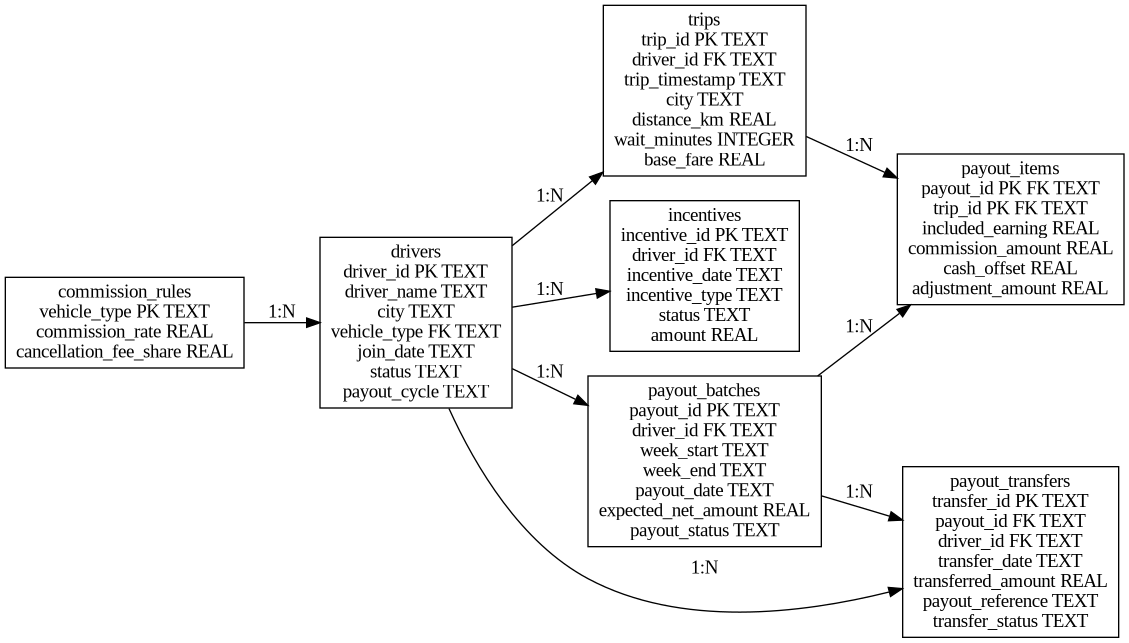

True

In [11]:
ER_TABLES = {
    "commission_rules": [
        "vehicle_type PK TEXT",
        "commission_rate REAL",
        "cancellation_fee_share REAL"
    ],

    "drivers": [
        "driver_id PK TEXT",
        "driver_name TEXT",
        "city TEXT",
        "vehicle_type FK TEXT",
        "join_date TEXT",
        "status TEXT",
        "payout_cycle TEXT"
    ],

    "trips": [
        "trip_id PK TEXT",
        "driver_id FK TEXT",
        "trip_timestamp TEXT",
        "city TEXT",
        "distance_km REAL",
        "wait_minutes INTEGER",
        "base_fare REAL",
        "distance_charge REAL",
        "waiting_fee REAL",
        "toll_amount REAL",
        "cancellation_fee REAL",
        "gross_driver_earning REAL",
        "trip_status TEXT",
        "payment_mode TEXT",
        "cash_collected REAL",
        "settlement_status TEXT",
        "created_at TEXT"
    ],

    "incentives": [
        "incentive_id PK TEXT",
        "driver_id FK TEXT",
        "incentive_date TEXT",
        "incentive_type TEXT",
        "status TEXT",
        "amount REAL"
    ],

    "payout_batches": [
        "payout_id PK TEXT",
        "driver_id FK TEXT",
        "week_start TEXT",
        "week_end TEXT",
        "payout_date TEXT",
        "expected_net_amount REAL",
        "payout_status TEXT",
        "payout_reference TEXT"
    ],

    "payout_items": [
        "payout_id PK FK TEXT",
        "trip_id PK FK TEXT",
        "included_earning REAL",
        "commission_amount REAL",
        "cash_offset REAL",
        "adjustment_amount REAL"
    ],

    "payout_transfers": [
        "transfer_id PK TEXT",
        "payout_id FK TEXT",
        "driver_id FK TEXT",
        "transfer_date TEXT",
        "transferred_amount REAL",
        "payout_reference TEXT",
        "transfer_status TEXT"
    ]
}



ER_RELATIONSHIPS = [
    ("drivers", "driver_id", "trips", "driver_id", "1:N"),

    ("commission_rules", "vehicle_type",
     "drivers", "vehicle_type", "1:N"),

    ("drivers", "driver_id", "incentives", "driver_id", "1:N"),

    ("drivers", "driver_id",
     "payout_batches", "driver_id", "1:N"),

    ("payout_batches", "payout_id",
     "payout_items", "payout_id", "1:N"),

    ("trips", "trip_id",
     "payout_items", "trip_id", "1:N"),

    ("payout_batches", "payout_id",
     "payout_transfers", "payout_id", "1:N"),

    ("drivers", "driver_id",
     "payout_transfers", "driver_id", "1:N")
]



validate_er(ER_TABLES, ER_RELATIONSHIPS)

### Expected Output — ER-1

- `ER design check: Passed`
- Seven connected core table boxes
- Primary and foreign keys shown in the table definitions
- `payout_items` uses the composite key `payout_id + trip_id`
- Eight required relationships render as arrows.

# 3. API Operations

The temporary internal API is already running. The SQL Developer consumes it using `requests`; no API server development is required.

In [12]:
import requests
import json
from IPython.display import display, Markdown

BASE_URL = "http://127.0.0.1:8765/api/v1"

session = requests.Session()
session.headers.update({"Content-Type": "application/json"})


def api_request(method, endpoint, **kwargs):
    """Send a request to the existing internal API."""
    url = f"{BASE_URL}{endpoint}"

    response = session.request(
        method=method,
        url=url,
        timeout=15,
        **kwargs
    )

    print(f"{method.upper()} {endpoint}")
    print(f"HTTP Status: {response.status_code}")

    try:
        response_data = response.json()
        print(json.dumps(response_data, indent=2))
    except ValueError:
        response_data = response.text
        print(response_data)

    return response, response_data



health_response, health_data = api_request("GET", "/health")

assert health_response.status_code == 200, \
    "API health check failed."

assert health_data.get("status") == "healthy", \
    "API is not reporting healthy status."

print("\nAPI health check: Passed")

GET /health
HTTP Status: 200
{
  "status": "healthy",
  "service": "internal-api-simulator"
}

API health check: Passed


## API-Q1 — Fetch Filtered Completed UPI Trips

Fetch exactly five trips using `GET` with `limit=5`, `payment_mode=UPI`, and `trip_status=COMPLETED`.

In [13]:
import requests
import pandas as pd
from IPython.display import display


params = {
    "limit": 5,
    "payment_mode": "UPI",
    "trip_status": "COMPLETED"
}

try:

    response = requests.get(
        f"{BASE_URL}/trips",
        params=params,
        timeout=10
    )

    print("HTTP Status:", response.status_code)


    response.raise_for_status()
    payload = response.json()


    trips = payload.get("data", []) if isinstance(payload, dict) else []


    display(pd.DataFrame(trips))


    status_ok = response.status_code == 200
    count_ok = len(trips) == 5
    payment_ok = all(
        trip.get("payment_mode") == "UPI"
        for trip in trips
    )
    trip_status_ok = all(
        trip.get("trip_status") == "COMPLETED"
        for trip in trips
    )


    checks = [
        {
            "Check": "HTTP status is 200",
            "Result": "Passed" if status_ok else "Failed"
        },
        {
            "Check": "Exactly 5 records returned",
            "Result": "Passed" if count_ok else "Failed"
        },
        {
            "Check": "Every payment_mode is UPI",
            "Result": "Passed" if payment_ok else "Failed"
        },
        {
            "Check": "Every trip_status is COMPLETED",
            "Result": "Passed" if trip_status_ok else "Failed"
        }
    ]

    overall_passed = all([
        status_ok,
        count_ok,
        payment_ok,
        trip_status_ok
    ])

    display(pd.DataFrame(checks))


    if "activity_status" in globals():
        activity_status["API-Q1"] = (
            "Passed" if overall_passed else "Needs Review"
        )

    print(
        "API-Q1:",
        "Passed" if overall_passed else "Needs Review"
    )

except requests.RequestException as error:
    if "activity_status" in globals():
        activity_status["API-Q1"] = "Needs Review"

    print("API request failed:", error)

except (ValueError, TypeError, AttributeError) as error:
    if "activity_status" in globals():
        activity_status["API-Q1"] = "Needs Review"

    print("Response validation failed:", error)

HTTP Status: 200


,trip_id,driver_id,trip_timestamp,city,distance_km,wait_minutes,base_fare,distance_charge,waiting_fee,toll_amount,cancellation_fee,gross_driver_earning,trip_status,payment_mode,cash_collected,settlement_status,created_at
0,TRP000001,DRV0044,2026-07-01 08:45:00,Hyderabad,22.84,3,54.52,260.05,0.00,0,0.00,314.57,COMPLETED,UPI,0.00,SETTLED,2026-07-01 08:45:00
1,TRP000003,DRV0042,2026-07-09 10:13:00,Mumbai,4.74,13,45.33,51.02,20.00,75,0.00,191.35,COMPLETED,UPI,0.00,SETTLED,2026-07-09 10:13:00
2,TRP000004,DRV0070,2026-07-08 09:21:00,Pune,24.84,5,40.55,345.82,4.00,20,0.00,410.37,COMPLETED,UPI,0.00,SETTLED,2026-07-08 09:21:00
3,TRP000005,DRV0009,2026-07-28 04:47:00,Bengaluru,27.99,13,62.28,354.01,20.00,0,0.00,436.29,COMPLETED,UPI,0.00,UNSETTLED,2026-07-28 04:47:00
4,TRP000006,DRV0024,2026-07-23 07:43:00,Ahmedabad,19.10,4,35.34,174.94,2.00,35,0.00,247.28,COMPLETED,UPI,0.00,UNSETTLED,2026-07-23 07:43:00


,Check,Result
0,HTTP status is 200,Passed
1,Exactly 5 records returned,Passed
2,Every payment_mode is UPI,Passed
3,Every trip_status is COMPLETED,Passed


API-Q1: Passed


### Expected Output — API-Q1

- HTTP `200`
- Exactly `5` records
- Every row has `payment_mode = UPI`
- Every row has `trip_status = COMPLETED`

**Hint:** Use `requests.get(..., params={...}, timeout=10)`.

## API-Q2 — Create a Trip with POST

Create the provided trip record after the reset helper removes any older practice record.

In [14]:
import requests
import pandas as pd
from IPython.display import display

TRIP_ID = "TRP_API_POST_001"


remove_api_practice_record(TRIP_ID)

new_trip_payload = base_practice_trip(TRIP_ID)

new_trip_payload["gross_driver_earning"] = 224.00

response = requests.post(
    f"{BASE_URL}/trips",
    json=new_trip_payload,
    timeout=10
)

print("HTTP Status:", response.status_code)

try:
    result = response.json()
except ValueError:
    result = {}

print("API Response:")
display(pd.DataFrame([result.get("data", result)]))

created_record = result.get("data", result)

created_id = created_record.get("trip_id")
gross_earning = created_record.get("gross_driver_earning")

status_ok = response.status_code == 201
id_ok = created_id == TRIP_ID
earning_ok = (
    gross_earning is not None
    and round(float(gross_earning), 2) == 224.00
)

checks = [
    {
        "Check": "HTTP status is 201",
        "Result": "Passed" if status_ok else "Failed"
    },
    {
        "Check": "Created ID is TRP_API_POST_001",
        "Result": "Passed" if id_ok else "Failed"
    },
    {
        "Check": "Gross driver earning is 224.00",
        "Result": "Passed" if earning_ok else "Failed"
    }
]

overall_passed = all([status_ok, id_ok, earning_ok])

display(pd.DataFrame(checks))

if "activity_status" in globals():
    activity_status["API-Q2"] = (
        "Passed" if overall_passed else "Needs Review"
    )

print("Overall status:", "Passed" if overall_passed else "Needs Review")


HTTP Status: 201
API Response:


,trip_id,driver_id,trip_timestamp,city,distance_km,wait_minutes,base_fare,distance_charge,waiting_fee,toll_amount,cancellation_fee,gross_driver_earning,trip_status,payment_mode,cash_collected,settlement_status,created_at
0,TRP_API_POST_001,DRV0001,2026-07-15 10:00:00,Bengaluru,8.40,4,50.00,100.00,2.00,0.00,0.00,224.00,COMPLETED,UPI,0.00,UNSETTLED,2026-07-15 10:00:00


,Check,Result
0,HTTP status is 201,Passed
1,Created ID is TRP_API_POST_001,Passed
2,Gross driver earning is 224.00,Passed


Overall status: Passed


### Expected Output — API-Q2

- HTTP `201`
- Created ID `TRP_API_POST_001`
- Gross driver earning `224.00`
- Overall status `Passed`

**Hint:** Use `json=new_trip_payload`.

## API-Q3 — Replace a Complete Trip with PUT

Reset `TRP_API_PUT_001`, then completely replace it using the provided payload.

In [15]:
import requests
import pandas as pd

TRIP_ID = "TRP_API_PUT_001"
url = f"{BASE_URL}/trips/{TRIP_ID}"

reset_api_practice_record(TRIP_ID)

put_payload = base_practice_trip(TRIP_ID).copy()

put_payload.update({
    "driver_id": "DRV0002",
    "payment_mode": "CARD",

    "base_fare": 100.00,
    "distance_charge": 180.00,
    "waiting_fee": 5.00,
    "toll_amount": 20.00,
    "cancellation_fee": 0.00,
    "gross_driver_earning": 305.00
})

try:
    response = requests.put(
        url,
        json=put_payload,
        timeout=15
    )

    print("HTTP Status Code:", response.status_code)

    response_body = response.json()
    returned_trip = (
        response_body.get("data", response_body)
        if isinstance(response_body, dict)
        else {}
    )

    if isinstance(returned_trip, list):
        returned_trip = returned_trip[0] if returned_trip else {}

    if not isinstance(returned_trip, dict):
        returned_trip = {}

    if returned_trip:
        display(pd.DataFrame([returned_trip]))
    else:
        print("No trip record was returned.")
        print(response.text)

    required_fields = set(put_payload.keys())
    returned_fields = set(returned_trip.keys())

    http_ok = response.status_code == 200
    driver_ok = returned_trip.get("driver_id") == "DRV0002"
    payment_ok = returned_trip.get("payment_mode") == "CARD"

    try:
        earning_ok = (
            round(float(returned_trip["gross_driver_earning"]), 2)
            == 305.00
        )
    except (KeyError, TypeError, ValueError):
        earning_ok = False

    fields_ok = required_fields.issubset(returned_fields)

    no_extra_fields = returned_fields == required_fields

    checks = [
        {"check": "HTTP status is 200",
         "status": "Passed" if http_ok else "Needs Review"},

        {"check": "driver_id = DRV0002",
         "status": "Passed" if driver_ok else "Needs Review"},

        {"check": "payment_mode = CARD",
         "status": "Passed" if payment_ok else "Needs Review"},

        {"check": "gross_driver_earning = 305.00",
         "status": "Passed" if earning_ok else "Needs Review"},

        {"check": "All required fields are present",
         "status": "Passed" if fields_ok else "Needs Review"},

        {"check": "No extra fields remain after replacement",
         "status": "Passed" if no_extra_fields else "Needs Review"}
    ]

    overall_passed = all([
        http_ok,
        driver_ok,
        payment_ok,
        earning_ok,
        fields_ok,
        no_extra_fields
    ])

    activity_status["API-Q3"] = (
        "Passed" if overall_passed else "Needs Review"
    )

    checks.append({
        "check": "Overall",
        "status": activity_status["API-Q3"]
    })

    display(pd.DataFrame(checks))

    if not no_extra_fields:
        print("Unexpected fields:", sorted(returned_fields - required_fields))
        print("Missing fields:", sorted(required_fields - returned_fields))

except requests.RequestException as e:
    activity_status["API-Q3"] = "Needs Review"
    print("API request failed:", e)

except ValueError as e:
    activity_status["API-Q3"] = "Needs Review"
    print("Could not parse the API response:", e)

HTTP Status Code: 200


,trip_id,driver_id,trip_timestamp,city,distance_km,wait_minutes,base_fare,distance_charge,waiting_fee,toll_amount,cancellation_fee,gross_driver_earning,trip_status,payment_mode,cash_collected,settlement_status,created_at
0,TRP_API_PUT_001,DRV0002,2026-07-15 10:00:00,Bengaluru,8.40,4,100.00,180.00,5.00,20.00,0.00,305.00,COMPLETED,CARD,0.00,UNSETTLED,2026-07-15 10:00:00


,check,status
0,HTTP status is 200,Passed
1,driver_id = DRV0002,Passed
2,payment_mode = CARD,Passed
3,gross_driver_earning = 305.00,Passed
4,All required fields are present,Passed
5,No extra fields remain after replacement,Passed
6,Overall,Passed


### Expected Output — API-Q3

- HTTP `200`
- `driver_id = DRV0002`
- `payment_mode = CARD`
- `gross_driver_earning = 305.00`
- All required trip fields are present; no old fields remain.

**Hint:** PUT sends the entire resource.

## API-Q4 — Update Selected Fields with PATCH

Change only `trip_status` and `settlement_status` for the reset practice record.

In [16]:
import requests
import pandas as pd

TRIP_ID = "TRP_API_PATCH_001"
url = f"{BASE_URL}/trips/{TRIP_ID}"

reset_api_practice_record(TRIP_ID)

def extract_trip_record(response):
    payload = response.json()

    if isinstance(payload, dict):
        record = payload.get("data", payload)
    else:
        record = payload

    if isinstance(record, list):
        record = record[0] if record else {}

    return record if isinstance(record, dict) else {}


try:

    before_response = requests.get(url, timeout=15)

    print("Before PATCH - HTTP Status:", before_response.status_code)

    if before_response.status_code != 200:
        raise RuntimeError(
            f"Could not fetch the reset trip: {before_response.text}"
        )

    before_record = extract_trip_record(before_response)

    patch_payload = {
        "trip_status": "COMPLETED",
        "settlement_status": "SETTLED"
    }

    patch_response = requests.patch(
        url,
        json=patch_payload,
        timeout=15
    )

    print("PATCH HTTP Status:", patch_response.status_code)

    after_response = requests.get(url, timeout=15)

    if after_response.status_code != 200:
        raise RuntimeError(
            f"Could not verify the updated trip: {after_response.text}"
        )

    after_record = extract_trip_record(after_response)

    display(pd.DataFrame([after_record]))

    http_ok = patch_response.status_code == 200

    trip_status_ok = (
        after_record.get("trip_status") == "COMPLETED"
    )

    settlement_status_ok = (
        after_record.get("settlement_status") == "SETTLED"
    )

    targeted_fields = {"trip_status", "settlement_status"}

    untargeted_fields = (
        set(before_record.keys()) | set(after_record.keys())
    ) - targeted_fields

    unchanged_ok = all(
        before_record.get(field) == after_record.get(field)
        for field in untargeted_fields
    )

    checks = [
        {
            "check": "PATCH HTTP status is 200",
            "status": "Passed" if http_ok else "Needs Review"
        },
        {
            "check": "trip_status = COMPLETED",
            "status": "Passed" if trip_status_ok else "Needs Review"
        },
        {
            "check": "settlement_status = SETTLED",
            "status": "Passed" if settlement_status_ok else "Needs Review"
        },
        {
            "check": "Untargeted fields remain unchanged",
            "status": "Passed" if unchanged_ok else "Needs Review"
        }
    ]

    overall_passed = all([
        http_ok,
        trip_status_ok,
        settlement_status_ok,
        unchanged_ok
    ])

    activity_status["API-Q4"] = (
        "Passed" if overall_passed else "Needs Review"
    )

    checks.append({
        "check": "Overall",
        "status": activity_status["API-Q4"]
    })

    display(pd.DataFrame(checks))

except (requests.RequestException, ValueError, RuntimeError) as e:
    activity_status["API-Q4"] = "Needs Review"
    print("API-Q4 error:", e)

Before PATCH - HTTP Status: 200
PATCH HTTP Status: 200


,trip_id,driver_id,trip_timestamp,city,distance_km,wait_minutes,base_fare,distance_charge,waiting_fee,toll_amount,cancellation_fee,gross_driver_earning,trip_status,payment_mode,cash_collected,settlement_status,created_at
0,TRP_API_PATCH_001,DRV0001,2026-07-15 10:00:00,Bengaluru,8.40,4,50.00,100.00,2.00,0.00,0.00,152.00,COMPLETED,UPI,0.00,SETTLED,2026-07-15 10:00:00


,check,status
0,PATCH HTTP status is 200,Passed
1,trip_status = COMPLETED,Passed
2,settlement_status = SETTLED,Passed
3,Untargeted fields remain unchanged,Passed
4,Overall,Passed


### Expected Output — API-Q4

- HTTP `200`
- Targeted settlement field changes to `SETTLED`
- Untargeted fields remain unchanged

**Hint:** PATCH sends only the fields that must change.

## API-Q5 — GET → DELETE → GET Verification

Reset one practice trip, read it, delete it, and read it again to prove `200 → 200 → 404`.

In [17]:
import requests
import pandas as pd

TRIP_ID = "TRP_API_DELETE_001"
url = f"{BASE_URL}/trips/{TRIP_ID}"

try:
    reset_api_practice_record(TRIP_ID)

    get_before = requests.get(url, timeout=15)

    print("GET before deletion:", get_before.status_code)

    delete_response = requests.delete(url, timeout=15)

    print("DELETE:", delete_response.status_code)

    get_after = requests.get(url, timeout=15)

    print("GET after deletion:", get_after.status_code)

    checks = [
        {
            "Request": "GET before deletion",
            "Expected HTTP status": 200,
            "Actual HTTP status": get_before.status_code,
            "Status": (
                "Passed" if get_before.status_code == 200
                else "Needs Review"
            )
        },
        {
            "Request": "DELETE",
            "Expected HTTP status": 200,
            "Actual HTTP status": delete_response.status_code,
            "Status": (
                "Passed" if delete_response.status_code == 200
                else "Needs Review"
            )
        },
        {
            "Request": "GET after deletion",
            "Expected HTTP status": 404,
            "Actual HTTP status": get_after.status_code,
            "Status": (
                "Passed" if get_after.status_code == 404
                else "Needs Review"
            )
        }
    ]

    overall_passed = (
        get_before.status_code == 200
        and delete_response.status_code == 200
        and get_after.status_code == 404
    )

    activity_status["API-Q5"] = (
        "Passed" if overall_passed else "Needs Review"
    )

    display(pd.DataFrame(checks))

    print("Expected sequence: 200 → 200 → 404")
    print("Overall status:", activity_status["API-Q5"])

except (requests.RequestException, KeyError, NameError) as e:
    activity_status["API-Q5"] = "Needs Review"
    print("API-Q5 error:", e)

GET before deletion: 200
DELETE: 200
GET after deletion: 404


,Request,Expected HTTP status,Actual HTTP status,Status
0,GET before deletion,200,200,Passed
1,DELETE,200,200,Passed
2,GET after deletion,404,404,Passed


Expected sequence: 200 → 200 → 404
Overall status: Passed


### Expected Output — API-Q5

| Request | Expected HTTP status |
|---|---:|
| GET before deletion | 200 |
| DELETE | 200 |
| GET after deletion | 404 |

**Hint:** Use the same resource URL for all three requests.

# 4. SQL Developer Questions

Write SQL only inside the provided triple-quoted strings. Do not use Pandas to calculate business answers. Standard non-recursive CTEs and SQLite-supported window functions are expected.

In [18]:
schema_catalog=build_schema_catalog(conn); display(schema_catalog); TABLE_TO_PREVIEW='trips'; display(run_query(f'SELECT * FROM {TABLE_TO_PREVIEW} LIMIT 5'))

,table,column,type,not_null,primary_key
0,api_ingestion_runs,run_id,INTEGER,False,True
1,api_ingestion_runs,resource,TEXT,True,False
2,api_ingestion_runs,started_at,TEXT,True,False
3,api_ingestion_runs,ended_at,TEXT,True,False
4,api_ingestion_runs,rows_received,INTEGER,True,False
...,...,...,...,...,...
73,trips,trip_status,TEXT,True,False
74,trips,payment_mode,TEXT,True,False
75,trips,cash_collected,REAL,True,False
76,trips,settlement_status,TEXT,True,False


,trip_id,driver_id,trip_timestamp,city,distance_km,wait_minutes,base_fare,distance_charge,waiting_fee,toll_amount,cancellation_fee,gross_driver_earning,trip_status,payment_mode,cash_collected,settlement_status,created_at
0,TRP000001,DRV0044,2026-07-01 08:45:00,Hyderabad,22.84,3,54.52,260.05,0.00,0.00,0.00,314.57,COMPLETED,UPI,0.00,SETTLED,2026-07-01 08:45:00
1,TRP000002,DRV0015,2026-07-12 15:22:00,Kolkata,1.72,16,38.33,17.55,26.00,35.00,0.00,116.88,COMPLETED,CASH,116.88,SETTLED,2026-07-12 15:22:00
2,TRP000003,DRV0042,2026-07-09 10:13:00,Mumbai,4.74,13,45.33,51.02,20.00,75.00,0.00,191.35,COMPLETED,UPI,0.00,SETTLED,2026-07-09 10:13:00
3,TRP000004,DRV0070,2026-07-08 09:21:00,Pune,24.84,5,40.55,345.82,4.00,20.00,0.00,410.37,COMPLETED,UPI,0.00,SETTLED,2026-07-08 09:21:00
4,TRP000005,DRV0009,2026-07-28 04:47:00,Bengaluru,27.99,13,62.28,354.01,20.00,0.00,0.00,436.29,COMPLETED,UPI,0.00,UNSETTLED,2026-07-28 04:47:00


## 4A. SQL Foundations and Multiple Tables

### Q1 — Largest Completed Trip Earnings

**Business requirement:** Driver Operations wants the ten largest completed driver earnings for a rapid payout review.

**Tables to use:** `trips`, `drivers`

**How to approach:** Join trips to drivers, filter completed trips, sort descending by gross driver earning, and limit to ten.

**Hint:** Use `JOIN`, `WHERE`, `ORDER BY`, and `LIMIT`.


In [19]:
q1_sql = r"""
SELECT
    t.trip_id,
    d.driver_name,
    t.city,
    d.vehicle_type,
    t.gross_driver_earning,
    t.payment_mode
FROM trips AS t
INNER JOIN drivers AS d
    ON t.driver_id = d.driver_id
WHERE t.trip_status = 'COMPLETED'
ORDER BY
    t.gross_driver_earning DESC,
    t.trip_id ASC
LIMIT 10;

"""

q1 = run_developer_query('Q1', q1_sql)


,trip_id,driver_name,city,vehicle_type,gross_driver_earning,payment_mode
0,TRP000488,Karan Verma 40,Ahmedabad,BIKE,592.53,UPI
1,TRP000942,Sameer Mehta 51,Delhi,CAR,549.03,WALLET
2,TRP000080,Varun Nair 32,Ahmedabad,AUTO,546.26,CARD
3,TRP001419,Aarav Reddy 14,Pune,AUTO,538.54,CASH
4,TRP000680,Ravi Kumar 53,Chennai,AUTO,536.98,WALLET
5,TRP000140,Vikram Singh 18,Mumbai,CAR,533.30,WALLET
6,TRP001187,Amit Das 19,Delhi,BIKE,532.94,UPI
7,TRP000777,Nikhil Sharma 60,Hyderabad,CAR,532.38,CASH
8,TRP000432,Ishaan Kumar 56,Ahmedabad,AUTO,528.77,CARD
9,TRP000876,Sanjay Iyer 31,Kolkata,BIKE,525.04,UPI


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


#### Expected Output — Q1

| Column | Requirement |
|---|---|
| `trip_id` | Required output column |
| `driver_name` | Required output column |
| `city` | Required output column |
| `vehicle_type` | Required output column |
| `gross_driver_earning` | Required output column |
| `payment_mode` | Required output column |

- **Expected row count:** `10`
- **Stable first row/key result:** `['TRP000488', 'Karan Verma 40', 'Ahmedabad', 'BIKE', 592.53, 'UPI']`
- Validation checks exact columns, row count, and stable first row/key result.


### Q2 — Driver Earnings Aggregation with HAVING

**Business requirement:** City Operations wants drivers with at least 15 completed trips and more than INR 4,000 in gross driver earnings.

**Tables to use:** `drivers`, `trips`

**How to approach:** Aggregate completed trips per driver and apply both count and value thresholds in HAVING.

**Hint:** Use `COUNT`, `SUM`, `GROUP BY`, and `HAVING`.


In [66]:
q2_sql = r"""

SELECT
    d.driver_id,
    d.driver_name,
    d.city,
    COUNT(t.trip_id) AS completed_trips,
    ROUND(SUM(t.gross_driver_earning), 2) AS total_gross_earnings
FROM drivers AS d
INNER JOIN trips AS t
    ON d.driver_id = t.driver_id
WHERE t.trip_status = 'COMPLETED'
GROUP BY
    d.driver_id,
    d.driver_name,
    d.city
HAVING
    COUNT(t.trip_id) >= 15
    AND SUM(t.gross_driver_earning) > 4000
ORDER BY
    total_gross_earnings DESC,
    d.driver_id ASC;
"""


q2 = run_developer_query('Q2', q2_sql)


,driver_id,driver_name,city,completed_trips,total_gross_earnings
0,DRV0040,Karan Verma 40,Ahmedabad,27,"8,567.52"
1,DRV0032,Varun Nair 32,Ahmedabad,24,"7,647.19"
2,DRV0033,Sameer Reddy 33,Bengaluru,27,"7,553.03"
3,DRV0075,Rohan Joshi 75,Delhi,26,"6,570.36"
4,DRV0052,Vihaan Patel 52,Hyderabad,25,"6,434.83"
5,DRV0059,Vihaan Joshi 59,Delhi,21,"6,404.65"
6,DRV0045,Vikram Joshi 45,Chennai,23,"6,214.85"
7,DRV0071,Aarav Gupta 71,Kolkata,25,"6,138.48"
8,DRV0022,Ankit Iyer 22,Pune,21,"6,065.63"
9,DRV0015,Kabir Gupta 15,Kolkata,22,"5,931.38"


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


#### Expected Output — Q2

| Column | Requirement |
|---|---|
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `city` | Required output column |
| `completed_trips` | Required output column |
| `total_gross_earnings` | Required output column |

- **Expected row count:** `46`
- **Stable first row/key result:** `['DRV0040', 'Karan Verma 40', 'Ahmedabad', 27, 8567.52]`
- Validation checks exact columns, row count, and stable first row/key result.


### Q3 — Weekly Payout Reconciliation

**Business requirement:** Driver Payments wants every weekly payout classified as MATCHED, MISSING, or MISMATCHED against transfer records.

**Tables to use:** `payout_batches`, `drivers`, `payout_transfers`

**How to approach:** Left join transfers, aggregate transfer value, use COALESCE for missing data, and classify with CASE.

**Hint:** Use `LEFT JOIN`, `COALESCE`, `SUM`, and `CASE`.


In [22]:
q3_sql = r"""

SELECT
    pb.payout_id,
    d.driver_name,
    pb.week_end,
    ROUND(pb.expected_net_amount, 2) AS expected_net_amount,
    ROUND(COALESCE(SUM(pt.transferred_amount), 0), 2)
        AS transferred_amount,
    CASE
        WHEN COUNT(pt.transfer_id) = 0
            THEN 'MISSING'
        WHEN ABS(
            COALESCE(SUM(pt.transferred_amount), 0)
            - pb.expected_net_amount
        ) <= 1.00
            THEN 'MATCHED'
        ELSE 'MISMATCHED'
    END AS payout_result
FROM payout_batches AS pb
INNER JOIN drivers AS d
    ON pb.driver_id = d.driver_id
LEFT JOIN payout_transfers AS pt
    ON pb.payout_id = pt.payout_id
GROUP BY
    pb.payout_id,
    d.driver_name,
    pb.week_end,
    pb.expected_net_amount
ORDER BY
    pb.payout_id ASC;


"""

q3 = run_developer_query('Q3', q3_sql)


,payout_id,driver_name,week_end,expected_net_amount,transferred_amount,payout_result
0,PAY00001,Kabir Reddy 01,2026-07-07,391.69,391.69,MATCHED
1,PAY00002,Kabir Reddy 01,2026-07-14,815.44,815.44,MATCHED
2,PAY00003,Kabir Reddy 01,2026-07-21,"1,308.59","1,308.59",MATCHED
3,PAY00004,Kabir Reddy 01,2026-07-28,0.00,0.00,MATCHED
4,PAY00005,Kabir Reddy 01,2026-07-31,487.14,487.14,MATCHED
...,...,...,...,...,...,...
365,PAY00366,Karan Reddy 80,2026-07-07,540.62,540.62,MATCHED
366,PAY00367,Karan Reddy 80,2026-07-14,161.05,161.05,MATCHED
367,PAY00368,Karan Reddy 80,2026-07-21,618.96,618.96,MATCHED
368,PAY00369,Karan Reddy 80,2026-07-28,227.72,227.72,MATCHED


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


#### Expected Output — Q3

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `driver_name` | Required output column |
| `week_end` | Required output column |
| `expected_net_amount` | Required output column |
| `transferred_amount` | Required output column |
| `payout_result` | Required output column |

- **Expected row count:** `370`
- **Stable first row/key result:** `['PAY00001', 'Kabir Reddy 01', '2026-07-07', 391.69, 391.69, 'MATCHED']`
- Validation checks exact columns, row count, and stable first row/key result.


### Q4 — Payouts with No Transfer

**Business requirement:** Payments Control needs payout batches that have no transfer record at all.

**Tables to use:** `payout_batches`, `drivers`, `payout_transfers`

**How to approach:** Left join the transfer table and keep only rows where the right-side key is NULL.

**Hint:** Use a `LEFT JOIN` NULL anti-join.


In [23]:
q4_sql = r"""

SELECT
    pb.payout_id,
    pb.driver_id,
    d.driver_name,
    pb.week_end,
    ROUND(pb.expected_net_amount, 2) AS expected_net_amount
FROM payout_batches AS pb
INNER JOIN drivers AS d
    ON pb.driver_id = d.driver_id
LEFT JOIN payout_transfers AS pt
    ON pb.payout_id = pt.payout_id
WHERE pt.transfer_id IS NULL
ORDER BY pb.payout_id ASC;

"""

q4 = run_developer_query('Q4', q4_sql)


,payout_id,driver_id,driver_name,week_end,expected_net_amount
0,PAY00014,DRV0004,Ishaan Patel 04,2026-07-07,895.20
1,PAY00084,DRV0019,Amit Das 19,2026-07-31,0.00
2,PAY00089,DRV0020,Manish Iyer 20,2026-07-31,951.49
3,PAY00091,DRV0021,Kabir Joshi 21,2026-07-14,"1,715.06"
4,PAY00098,DRV0022,Ankit Iyer 22,2026-07-28,829.30
5,PAY00100,DRV0023,Manish Sharma 23,2026-07-07,385.30
6,PAY00116,DRV0026,Ishaan Patel 26,2026-07-14,0.00
7,PAY00123,DRV0027,Deepak Patel 27,2026-07-28,742.15
8,PAY00131,DRV0029,Aditya Gupta 29,2026-07-14,585.01
9,PAY00155,DRV0034,Aditya Singh 34,2026-07-14,269.30


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


#### Expected Output — Q4

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `week_end` | Required output column |
| `expected_net_amount` | Required output column |

- **Expected row count:** `29`
- **Stable first row/key result:** `['PAY00014', 'DRV0004', 'Ishaan Patel 04', '2026-07-07', 895.2]`
- Validation checks exact columns, row count, and stable first row/key result.


## 4B. SQL Functions, Set Operations, Subqueries, and CTEs

### Q5 — Drivers with Incentives and Open Exceptions

**Business requirement:** Driver Operations needs drivers who have both an approved incentive and at least one open settlement exception.

**Tables to use:** `drivers`, `incentives`, `settlement_exceptions`

**How to approach:** Build the two driver-id sets, intersect them, then join to driver details.

**Hint:** Use `INTERSECT` or an equivalent set operation.


In [24]:
q5_sql = r"""

WITH incentive_drivers AS (
    SELECT DISTINCT driver_id
    FROM incentives
    WHERE status = 'APPROVED'
),
exception_drivers AS (
    SELECT DISTINCT driver_id
    FROM settlement_exceptions
    WHERE status = 'OPEN'
),
eligible_drivers AS (
    SELECT driver_id
    FROM incentive_drivers

    INTERSECT

    SELECT driver_id
    FROM exception_drivers
)
SELECT
    d.driver_id,
    d.driver_name,
    d.city
FROM drivers AS d
INNER JOIN eligible_drivers AS ed
    ON d.driver_id = ed.driver_id
ORDER BY d.driver_id ASC;

"""

q5 = run_developer_query('Q5', q5_sql)


,driver_id,driver_name,city
0,DRV0001,Kabir Reddy 01,Bengaluru
1,DRV0003,Kabir Joshi 03,Delhi
2,DRV0004,Ishaan Patel 04,Hyderabad
3,DRV0005,Deepak Singh 05,Chennai
4,DRV0006,Karan Singh 06,Pune
...,...,...,...
72,DRV0076,Vihaan Gupta 76,Hyderabad
73,DRV0077,Karan Sharma 77,Chennai
74,DRV0078,Aditya Reddy 78,Pune
75,DRV0079,Aarav Iyer 79,Kolkata


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


#### Expected Output — Q5

| Column | Requirement |
|---|---|
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `city` | Required output column |

- **Expected row count:** `77`
- **Stable first row/key result:** `['DRV0001', 'Kabir Reddy 01', 'Bengaluru']`
- Validation checks exact columns, row count, and stable first row/key result.


### Q6 — Driver Risk Report with Essential Functions

**Business requirement:** Risk Operations needs a readable driver risk list using text transformation, date tenure, null handling, numeric exception exposure, and risk bands.

**Tables to use:** `drivers`, `settlement_exceptions`

**How to approach:** Use string functions for labels, julianday for tenure, conditional aggregation for open exceptions, COALESCE for missing values, CAST for whole-day tenure, and CASE for risk.

**Hint:** Use `UPPER`, `SUBSTR`, date functions, `COALESCE`, `CAST`, and `CASE`.


In [43]:
sql_q6 = """
WITH exception_summary AS (
    SELECT
        se.driver_id,
        SUM(
            CASE
                WHEN se.status = 'OPEN' THEN 1
                ELSE 0
            END
        ) AS open_exception_count,
        ROUND(
            SUM(
                CASE
                    WHEN se.status = 'OPEN' THEN
                        ABS(
                            COALESCE(se.expected_value, 0)
                            - COALESCE(se.actual_value, 0)
                        )
                    ELSE 0
                END
            ),
            2
        ) AS open_exception_value
    FROM settlement_exceptions AS se
    GROUP BY se.driver_id
),
driver_risk AS (
    SELECT
        d.driver_id,
        UPPER(d.driver_name) AS driver_label,
        UPPER(SUBSTR(d.city, 1, 3)) AS city_code,
        CAST(
            julianday('2026-08-03') - julianday(d.join_date)
            AS INTEGER
        ) AS days_active,
        COALESCE(es.open_exception_count, 0)
            AS open_exception_count,
        COALESCE(es.open_exception_value, 0.0)
            AS open_exception_value
    FROM drivers AS d
    LEFT JOIN exception_summary AS es
        ON d.driver_id = es.driver_id
)
SELECT
    driver_id,
    driver_label,
    city_code,
    days_active,
    open_exception_count,
    open_exception_value,
    CASE
        WHEN open_exception_count >= 5
             OR open_exception_value >= 1000
            THEN 'HIGH'
        WHEN open_exception_count >= 2
             OR open_exception_value >= 250
            THEN 'MEDIUM'
        ELSE 'LOW'
    END AS risk_band
FROM driver_risk
ORDER BY
    open_exception_count DESC,
    open_exception_value DESC,
    driver_id ASC;
"""

run_developer_query("Q6", sql_q6)



,driver_id,driver_label,city_code,days_active,open_exception_count,open_exception_value,risk_band
0,DRV0075,ROHAN JOSHI 75,DEL,537,8,"1,665.73",HIGH
1,DRV0026,ISHAAN PATEL 26,MUM,1265,7,"1,584.34",HIGH
2,DRV0024,KABIR PATEL 24,AHM,1240,7,"1,256.88",HIGH
3,DRV0054,ARJUN VERMA 54,PUN,304,6,"2,726.65",HIGH
4,DRV0045,VIKRAM JOSHI 45,CHE,1069,6,"2,503.21",HIGH
...,...,...,...,...,...,...,...
75,DRV0001,KABIR REDDY 01,BEN,383,1,2.00,LOW
76,DRV0030,RAHUL SHARMA 30,PUN,389,1,2.00,LOW
77,DRV0002,ISHAAN PATEL 02,MUM,429,0,0.00,LOW
78,DRV0049,ANKIT JOSHI 49,BEN,531,0,0.00,LOW


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,driver_id,driver_label,city_code,days_active,open_exception_count,open_exception_value,risk_band
0,DRV0075,ROHAN JOSHI 75,DEL,537,8,"1,665.73",HIGH
1,DRV0026,ISHAAN PATEL 26,MUM,1265,7,"1,584.34",HIGH
2,DRV0024,KABIR PATEL 24,AHM,1240,7,"1,256.88",HIGH
3,DRV0054,ARJUN VERMA 54,PUN,304,6,"2,726.65",HIGH
4,DRV0045,VIKRAM JOSHI 45,CHE,1069,6,"2,503.21",HIGH
...,...,...,...,...,...,...,...
75,DRV0001,KABIR REDDY 01,BEN,383,1,2.00,LOW
76,DRV0030,RAHUL SHARMA 30,PUN,389,1,2.00,LOW
77,DRV0002,ISHAAN PATEL 02,MUM,429,0,0.00,LOW
78,DRV0049,ANKIT JOSHI 49,BEN,531,0,0.00,LOW


#### Expected Output — Q6

| Column | Requirement |
|---|---|
| `driver_id` | Required output column |
| `driver_label` | Required output column |
| `city_code` | Required output column |
| `days_active` | Required output column |
| `open_exception_count` | Required output column |
| `open_exception_value` | Required output column |
| `risk_band` | Required output column |

- **Expected row count:** `80`
- **Stable first row/key result:** `['DRV0075', 'ROHAN JOSHI 75', 'DEL', 537, 8, 1665.73, 'HIGH']`
- Validation checks exact columns, row count, and stable first row/key result.


### Q7 — Drivers Above Average Completed Gross Earnings

**Business requirement:** Driver Performance wants drivers whose completed gross earnings exceed the average driver total.

**Tables to use:** `drivers`, `trips`

**How to approach:** Create one driver-total layer, compare each total with a scalar average subquery, then return driver details.

**Hint:** Use a standard CTE or derived table plus a scalar subquery.


In [28]:
sql_q7 = """
WITH driver_totals AS (
    SELECT
        d.driver_id,
        d.driver_name,
        d.city,
        ROUND(SUM(t.gross_driver_earning), 2) AS gross_value
    FROM drivers AS d
    INNER JOIN trips AS t
        ON d.driver_id = t.driver_id
    WHERE t.trip_status = 'COMPLETED'
    GROUP BY
        d.driver_id,
        d.driver_name,
        d.city
)
SELECT
    driver_id,
    driver_name,
    city,
    gross_value
FROM driver_totals
WHERE gross_value > (
    SELECT AVG(gross_value)
    FROM driver_totals
)
ORDER BY
    gross_value DESC,
    driver_id ASC;
"""

run_developer_query("Q7", sql_q7)

,driver_id,driver_name,city,gross_value
0,DRV0040,Karan Verma 40,Ahmedabad,"8,567.52"
1,DRV0032,Varun Nair 32,Ahmedabad,"7,647.19"
2,DRV0033,Sameer Reddy 33,Bengaluru,"7,553.03"
3,DRV0075,Rohan Joshi 75,Delhi,"6,570.36"
4,DRV0052,Vihaan Patel 52,Hyderabad,"6,434.83"
5,DRV0059,Vihaan Joshi 59,Delhi,"6,404.65"
6,DRV0045,Vikram Joshi 45,Chennai,"6,214.85"
7,DRV0071,Aarav Gupta 71,Kolkata,"6,138.48"
8,DRV0022,Ankit Iyer 22,Pune,"6,065.63"
9,DRV0015,Kabir Gupta 15,Kolkata,"5,931.38"


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,driver_id,driver_name,city,gross_value
0,DRV0040,Karan Verma 40,Ahmedabad,"8,567.52"
1,DRV0032,Varun Nair 32,Ahmedabad,"7,647.19"
2,DRV0033,Sameer Reddy 33,Bengaluru,"7,553.03"
3,DRV0075,Rohan Joshi 75,Delhi,"6,570.36"
4,DRV0052,Vihaan Patel 52,Hyderabad,"6,434.83"
5,DRV0059,Vihaan Joshi 59,Delhi,"6,404.65"
6,DRV0045,Vikram Joshi 45,Chennai,"6,214.85"
7,DRV0071,Aarav Gupta 71,Kolkata,"6,138.48"
8,DRV0022,Ankit Iyer 22,Pune,"6,065.63"
9,DRV0015,Kabir Gupta 15,Kolkata,"5,931.38"


#### Expected Output — Q7

| Column | Requirement |
|---|---|
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `city` | Required output column |
| `gross_value` | Required output column |

- **Expected row count:** `41`
- **Stable first row/key result:** `['DRV0040', 'Karan Verma 40', 'Ahmedabad', 8567.52]`
- Validation checks exact columns, row count, and stable first row/key result.


### Q8 — Recalculate Weekly Payouts with Multiple CTEs

**Business requirement:** Payments Control wants payout amounts independently recalculated from trip items and approved incentives, then compared with engine and transfer values.

**Tables to use:** `payout_batches`, `payout_items`, `incentives`, `payout_transfers`, `drivers`

**How to approach:** Create separate CTEs for trip net, incentives, and transfer totals; then join them to payout batches.

**Hint:** Use multiple standard CTEs; no recursion.


In [29]:
sql_q8 = """
WITH trip_net AS (
    SELECT
        pi.payout_id,
        SUM(
            COALESCE(pi.included_earning, 0)
            - COALESCE(pi.commission_amount, 0)
            - COALESCE(pi.cash_offset, 0)
            + COALESCE(pi.adjustment_amount, 0)
        ) AS trip_net_amount
    FROM payout_items AS pi
    GROUP BY pi.payout_id
),
approved_incentives AS (
    SELECT
        pb.payout_id,
        SUM(COALESCE(i.amount, 0)) AS incentive_amount
    FROM payout_batches AS pb
    LEFT JOIN incentives AS i
        ON i.driver_id = pb.driver_id
        AND i.incentive_date >= pb.week_start
        AND i.incentive_date <= pb.week_end
        AND i.status = 'APPROVED'
    GROUP BY pb.payout_id
),
transfer_totals AS (
    SELECT
        pt.payout_id,
        SUM(COALESCE(pt.transferred_amount, 0)) AS transferred_amount
    FROM payout_transfers AS pt
    GROUP BY pt.payout_id
),
payout_reconciliation AS (
    SELECT
        pb.payout_id,
        d.driver_name,
        ROUND(pb.expected_net_amount, 2) AS engine_amount,
        ROUND(
            COALESCE(tn.trip_net_amount, 0)
            + COALESCE(ai.incentive_amount, 0),
            2
        ) AS recalculated_amount,
        ROUND(COALESCE(tt.transferred_amount, 0), 2)
            AS transferred_amount
    FROM payout_batches AS pb
    INNER JOIN drivers AS d
        ON pb.driver_id = d.driver_id
    LEFT JOIN trip_net AS tn
        ON pb.payout_id = tn.payout_id
    LEFT JOIN approved_incentives AS ai
        ON pb.payout_id = ai.payout_id
    LEFT JOIN transfer_totals AS tt
        ON pb.payout_id = tt.payout_id
)
SELECT
    payout_id,
    driver_name,
    engine_amount,
    recalculated_amount,
    transferred_amount,
    CASE
        WHEN ABS(engine_amount - recalculated_amount) <= 0.01
            THEN 'ENGINE_OK'
        ELSE 'ENGINE_MISMATCH'
    END AS engine_check
FROM payout_reconciliation
ORDER BY payout_id ASC;
"""

run_developer_query("Q8", sql_q8)

,payout_id,driver_name,engine_amount,recalculated_amount,transferred_amount,engine_check
0,PAY00001,Kabir Reddy 01,391.69,391.69,391.69,ENGINE_OK
1,PAY00002,Kabir Reddy 01,815.44,815.44,815.44,ENGINE_OK
2,PAY00003,Kabir Reddy 01,"1,308.59","1,308.59","1,308.59",ENGINE_OK
3,PAY00004,Kabir Reddy 01,0.00,-32.23,0.00,ENGINE_MISMATCH
4,PAY00005,Kabir Reddy 01,487.14,487.14,487.14,ENGINE_OK
...,...,...,...,...,...,...
365,PAY00366,Karan Reddy 80,540.62,540.62,540.62,ENGINE_OK
366,PAY00367,Karan Reddy 80,161.05,161.05,161.05,ENGINE_OK
367,PAY00368,Karan Reddy 80,618.96,716.17,618.96,ENGINE_MISMATCH
368,PAY00369,Karan Reddy 80,227.72,227.72,227.72,ENGINE_OK


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,payout_id,driver_name,engine_amount,recalculated_amount,transferred_amount,engine_check
0,PAY00001,Kabir Reddy 01,391.69,391.69,391.69,ENGINE_OK
1,PAY00002,Kabir Reddy 01,815.44,815.44,815.44,ENGINE_OK
2,PAY00003,Kabir Reddy 01,"1,308.59","1,308.59","1,308.59",ENGINE_OK
3,PAY00004,Kabir Reddy 01,0.00,-32.23,0.00,ENGINE_MISMATCH
4,PAY00005,Kabir Reddy 01,487.14,487.14,487.14,ENGINE_OK
...,...,...,...,...,...,...
365,PAY00366,Karan Reddy 80,540.62,540.62,540.62,ENGINE_OK
366,PAY00367,Karan Reddy 80,161.05,161.05,161.05,ENGINE_OK
367,PAY00368,Karan Reddy 80,618.96,716.17,618.96,ENGINE_MISMATCH
368,PAY00369,Karan Reddy 80,227.72,227.72,227.72,ENGINE_OK


#### Expected Output — Q8

| Column | Requirement |
|---|---|
| `payout_id` | Required output column |
| `driver_name` | Required output column |
| `engine_amount` | Required output column |
| `recalculated_amount` | Required output column |
| `transferred_amount` | Required output column |
| `engine_check` | Required output column |

- **Expected row count:** `370`
- **Stable first row/key result:** `['PAY00001', 'Kabir Reddy 01', 391.69, 391.69, 391.69, 'ENGINE_OK']`
- Validation checks exact columns, row count, and stable first row/key result.


## 4C. Window Functions

### Q9 — City Driver Earnings Rank

**Business requirement:** City Operations wants drivers ranked by completed gross driver earnings within each city.

**Tables to use:** `drivers`, `trips`

**How to approach:** Aggregate per driver, then rank inside each city partition.

**Hint:** Use `RANK() OVER (PARTITION BY ...)`.


In [33]:
sql_q9 = """
WITH driver_earnings AS (
    SELECT
        d.city,
        d.driver_id,
        d.driver_name,
        ROUND(SUM(t.gross_driver_earning), 2) AS gross_value
    FROM drivers AS d
    INNER JOIN trips AS t
        ON d.driver_id = t.driver_id
    WHERE t.trip_status = 'COMPLETED'
    GROUP BY
        d.city,
        d.driver_id,
        d.driver_name
),
city_rankings AS (
    SELECT
        city,
        driver_id,
        driver_name,
        gross_value,
        RANK() OVER (
            PARTITION BY city
            ORDER BY gross_value DESC
        ) AS city_rank
    FROM driver_earnings
)
SELECT
    city,
    driver_id,
    driver_name,
    gross_value,
    city_rank
FROM city_rankings
ORDER BY
    city ASC,
    city_rank ASC,
    driver_id ASC;
"""

run_developer_query("Q9", sql_q9)

,city,driver_id,driver_name,gross_value,city_rank
0,Ahmedabad,DRV0040,Karan Verma 40,"8,567.52",1
1,Ahmedabad,DRV0032,Varun Nair 32,"7,647.19",2
2,Ahmedabad,DRV0048,Kabir Patel 48,"5,432.24",3
3,Ahmedabad,DRV0008,Deepak Kumar 08,"5,380.37",4
4,Ahmedabad,DRV0056,Ishaan Kumar 56,"5,060.28",5
...,...,...,...,...,...
75,Pune,DRV0070,Vikram Sharma 70,"4,774.89",6
76,Pune,DRV0054,Arjun Verma 54,"4,421.84",7
77,Pune,DRV0006,Karan Singh 06,"3,871.44",8
78,Pune,DRV0038,Aditya Kumar 38,"3,329.43",9


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,city,driver_id,driver_name,gross_value,city_rank
0,Ahmedabad,DRV0040,Karan Verma 40,"8,567.52",1
1,Ahmedabad,DRV0032,Varun Nair 32,"7,647.19",2
2,Ahmedabad,DRV0048,Kabir Patel 48,"5,432.24",3
3,Ahmedabad,DRV0008,Deepak Kumar 08,"5,380.37",4
4,Ahmedabad,DRV0056,Ishaan Kumar 56,"5,060.28",5
...,...,...,...,...,...
75,Pune,DRV0070,Vikram Sharma 70,"4,774.89",6
76,Pune,DRV0054,Arjun Verma 54,"4,421.84",7
77,Pune,DRV0006,Karan Singh 06,"3,871.44",8
78,Pune,DRV0038,Aditya Kumar 38,"3,329.43",9


#### Expected Output — Q9

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `gross_value` | Required output column |
| `city_rank` | Required output column |

- **Expected row count:** `80`
- **Stable first row/key result:** `['Ahmedabad', 'DRV0040', 'Karan Verma 40', 8567.52, 1]`
- Validation checks exact columns, row count, and stable first row/key result.


### Q10 — Daily Running Total and 7-Day Moving Average

**Business requirement:** Finance Operations wants daily net driver earnings, a cumulative total, and a seven-day moving average.

**Tables to use:** `trips`, `drivers`, `commission_rules`

**How to approach:** Aggregate daily completed-trip net earnings after commission, then apply window frames.

**Hint:** Use `SUM(...) OVER` and `AVG(...) OVER` with row frames.


In [45]:
sql_q10 = """
WITH daily_earnings AS (
    SELECT
        DATE(t.trip_timestamp) AS trip_date,
        COUNT(t.trip_id) AS completed_trips,
        ROUND(
            SUM(
                t.gross_driver_earning
                * (1 - COALESCE(cr.commission_rate, 0))
            ),
            2
        ) AS daily_net_earnings
    FROM trips AS t
    INNER JOIN drivers AS d
        ON t.driver_id = d.driver_id
    LEFT JOIN commission_rules AS cr
        ON d.vehicle_type = cr.vehicle_type
    WHERE t.trip_status = 'COMPLETED'
    GROUP BY DATE(t.trip_timestamp)
),
earnings_windows AS (
    SELECT
        trip_date,
        completed_trips,
        daily_net_earnings,
        ROUND(
            SUM(daily_net_earnings) OVER (
                ORDER BY trip_date
                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
            ),
            2
        ) AS cumulative_net_earnings,
        ROUND(
            AVG(daily_net_earnings) OVER (
                ORDER BY trip_date
                ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
            ),
            2
        ) AS seven_day_moving_avg
    FROM daily_earnings
)
SELECT
    trip_date,
    completed_trips,
    daily_net_earnings,
    cumulative_net_earnings,
    seven_day_moving_avg
FROM earnings_windows
ORDER BY trip_date ASC;
"""

run_developer_query("Q10", sql_q10)

,trip_date,completed_trips,daily_net_earnings,cumulative_net_earnings,seven_day_moving_avg
0,2026-07-01,42,"9,793.46","9,793.46","9,793.46"
1,2026-07-02,37,"7,938.83","17,732.29","8,866.15"
2,2026-07-03,44,"10,092.82","27,825.11","9,275.04"
3,2026-07-04,37,"8,235.57","36,060.68","9,015.17"
4,2026-07-05,42,"8,491.76","44,552.44","8,910.49"
5,2026-07-06,43,"9,643.45","54,195.89","9,032.65"
6,2026-07-07,33,"7,320.39","61,516.28","8,788.04"
7,2026-07-08,49,"11,525.87","73,042.15","9,035.53"
8,2026-07-09,43,"9,549.04","82,591.19","9,265.56"
9,2026-07-10,41,"10,136.48","92,727.67","9,271.79"


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,trip_date,completed_trips,daily_net_earnings,cumulative_net_earnings,seven_day_moving_avg
0,2026-07-01,42,"9,793.46","9,793.46","9,793.46"
1,2026-07-02,37,"7,938.83","17,732.29","8,866.15"
2,2026-07-03,44,"10,092.82","27,825.11","9,275.04"
3,2026-07-04,37,"8,235.57","36,060.68","9,015.17"
4,2026-07-05,42,"8,491.76","44,552.44","8,910.49"
5,2026-07-06,43,"9,643.45","54,195.89","9,032.65"
6,2026-07-07,33,"7,320.39","61,516.28","8,788.04"
7,2026-07-08,49,"11,525.87","73,042.15","9,035.53"
8,2026-07-09,43,"9,549.04","82,591.19","9,265.56"
9,2026-07-10,41,"10,136.48","92,727.67","9,271.79"


#### Expected Output — Q10

| Column | Requirement |
|---|---|
| `trip_date` | Required output column |
| `completed_trips` | Required output column |
| `daily_net_earnings` | Required output column |
| `cumulative_net_earnings` | Required output column |
| `seven_day_moving_avg` | Required output column |

- **Expected row count:** `31`
- **Stable first row/key result:** `['2026-07-01', 42, 9793.46, 9793.46, 9793.46]`
- Validation checks exact columns, row count, and stable first row/key result.


### Q11 — Day-over-Day Net Earnings Change

**Business requirement:** Finance Operations wants each day compared with the previous day, including absolute and percentage movement.

**Tables to use:** `trips`, `drivers`, `commission_rules`

**How to approach:** Build daily net earnings, use LAG for the previous day, then calculate safe changes.

**Hint:** Use `LAG` and protect division by zero.


In [46]:
sql_q11 = """
WITH daily_earnings AS (
    SELECT
        DATE(t.trip_timestamp) AS trip_date,
        ROUND(
            SUM(
                t.gross_driver_earning
                * (1 - COALESCE(cr.commission_rate, 0))
            ),
            2
        ) AS daily_net_earnings
    FROM trips AS t
    INNER JOIN drivers AS d
        ON t.driver_id = d.driver_id
    LEFT JOIN commission_rules AS cr
        ON d.vehicle_type = cr.vehicle_type
    WHERE t.trip_status = 'COMPLETED'
    GROUP BY DATE(t.trip_timestamp)
),
earnings_with_previous_day AS (
    SELECT
        trip_date,
        daily_net_earnings,
        LAG(daily_net_earnings) OVER (
            ORDER BY trip_date
        ) AS previous_day_earnings
    FROM daily_earnings
)
SELECT
    trip_date,
    daily_net_earnings,
    previous_day_earnings,
    ROUND(
        daily_net_earnings - previous_day_earnings,
        2
    ) AS absolute_change,
    ROUND(
        (
            (daily_net_earnings - previous_day_earnings)
            / NULLIF(previous_day_earnings, 0)
        ) * 100,
        2
    ) AS pct_change
FROM earnings_with_previous_day
ORDER BY trip_date ASC;
"""

run_developer_query("Q11", sql_q11)

,trip_date,daily_net_earnings,previous_day_earnings,absolute_change,pct_change
0,2026-07-01,"9,793.46",NaN,NaN,NaN
1,2026-07-02,"7,938.83","9,793.46","-1,854.63",-18.94
2,2026-07-03,"10,092.82","7,938.83","2,153.99",27.13
3,2026-07-04,"8,235.57","10,092.82","-1,857.25",-18.40
4,2026-07-05,"8,491.76","8,235.57",256.19,3.11
5,2026-07-06,"9,643.45","8,491.76","1,151.69",13.56
6,2026-07-07,"7,320.39","9,643.45","-2,323.06",-24.09
7,2026-07-08,"11,525.87","7,320.39","4,205.48",57.45
8,2026-07-09,"9,549.04","11,525.87","-1,976.83",-17.15
9,2026-07-10,"10,136.48","9,549.04",587.44,6.15


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,trip_date,daily_net_earnings,previous_day_earnings,absolute_change,pct_change
0,2026-07-01,"9,793.46",NaN,NaN,NaN
1,2026-07-02,"7,938.83","9,793.46","-1,854.63",-18.94
2,2026-07-03,"10,092.82","7,938.83","2,153.99",27.13
3,2026-07-04,"8,235.57","10,092.82","-1,857.25",-18.40
4,2026-07-05,"8,491.76","8,235.57",256.19,3.11
5,2026-07-06,"9,643.45","8,491.76","1,151.69",13.56
6,2026-07-07,"7,320.39","9,643.45","-2,323.06",-24.09
7,2026-07-08,"11,525.87","7,320.39","4,205.48",57.45
8,2026-07-09,"9,549.04","11,525.87","-1,976.83",-17.15
9,2026-07-10,"10,136.48","9,549.04",587.44,6.15


#### Expected Output — Q11

| Column | Requirement |
|---|---|
| `trip_date` | Required output column |
| `daily_net_earnings` | Required output column |
| `previous_day_earnings` | Required output column |
| `absolute_change` | Required output column |
| `pct_change` | Required output column |

- **Expected row count:** `31`
- **Stable first row/key result:** `['2026-07-01', 9793.46, None, None, None]`
- Validation checks exact columns, row count, and stable first row/key result.


### Q12 — First and Latest Completed Trip per Driver

**Business requirement:** Driver Support needs the first and latest completed trip for every driver.

**Tables to use:** `trips`, `drivers`

**How to approach:** Assign forward and reverse row numbers per driver, then use conditional aggregation.

**Hint:** Use `ROW_NUMBER()` plus conditional aggregation.


In [47]:
sql_q12 = """
WITH ranked_trips AS (
    SELECT
        t.driver_id,
        t.trip_id,
        t.trip_timestamp,

        ROW_NUMBER() OVER (
            PARTITION BY t.driver_id
            ORDER BY
                t.trip_timestamp ASC,
                t.trip_id ASC
        ) AS first_rank,

        ROW_NUMBER() OVER (
            PARTITION BY t.driver_id
            ORDER BY
                t.trip_timestamp DESC,
                t.trip_id DESC
        ) AS latest_rank

    FROM trips AS t
    WHERE t.trip_status = 'COMPLETED'
)
SELECT
    d.driver_id,
    d.driver_name,

    MAX(
        CASE
            WHEN rt.first_rank = 1
            THEN rt.trip_id
        END
    ) AS first_trip_id,

    MAX(
        CASE
            WHEN rt.first_rank = 1
            THEN rt.trip_timestamp
        END
    ) AS first_trip_timestamp,

    MAX(
        CASE
            WHEN rt.latest_rank = 1
            THEN rt.trip_id
        END
    ) AS latest_trip_id,

    MAX(
        CASE
            WHEN rt.latest_rank = 1
            THEN rt.trip_timestamp
        END
    ) AS latest_trip_timestamp

FROM drivers AS d
LEFT JOIN ranked_trips AS rt
    ON d.driver_id = rt.driver_id

GROUP BY
    d.driver_id,
    d.driver_name

ORDER BY d.driver_id ASC;
"""

run_developer_query("Q12", sql_q12)

,driver_id,driver_name,first_trip_id,first_trip_timestamp,latest_trip_id,latest_trip_timestamp
0,DRV0001,Kabir Reddy 01,TRP000398,2026-07-03 08:05:00,TRP001364,2026-07-30 15:38:00
1,DRV0002,Ishaan Patel 02,TRP000144,2026-07-02 14:39:00,TRP000428,2026-07-28 22:36:00
2,DRV0003,Kabir Joshi 03,TRP001077,2026-07-03 09:54:00,TRP000062,2026-07-30 08:33:00
3,DRV0004,Ishaan Patel 04,TRP001028,2026-07-01 01:07:00,TRP000993,2026-07-26 08:06:00
4,DRV0005,Deepak Singh 05,TRP000671,2026-07-01 09:29:00,TRP000110,2026-07-30 22:41:00
...,...,...,...,...,...,...
75,DRV0076,Vihaan Gupta 76,TRP000402,2026-07-02 05:25:00,TRP000758,2026-07-30 14:34:00
76,DRV0077,Karan Sharma 77,TRP000921,2026-07-04 01:32:00,TRP000922,2026-07-24 06:30:00
77,DRV0078,Aditya Reddy 78,TRP000624,2026-07-11 22:50:00,TRP000270,2026-07-31 16:08:00
78,DRV0079,Aarav Iyer 79,TRP001249,2026-07-03 06:33:00,TRP001291,2026-07-31 21:13:00


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,driver_id,driver_name,first_trip_id,first_trip_timestamp,latest_trip_id,latest_trip_timestamp
0,DRV0001,Kabir Reddy 01,TRP000398,2026-07-03 08:05:00,TRP001364,2026-07-30 15:38:00
1,DRV0002,Ishaan Patel 02,TRP000144,2026-07-02 14:39:00,TRP000428,2026-07-28 22:36:00
2,DRV0003,Kabir Joshi 03,TRP001077,2026-07-03 09:54:00,TRP000062,2026-07-30 08:33:00
3,DRV0004,Ishaan Patel 04,TRP001028,2026-07-01 01:07:00,TRP000993,2026-07-26 08:06:00
4,DRV0005,Deepak Singh 05,TRP000671,2026-07-01 09:29:00,TRP000110,2026-07-30 22:41:00
...,...,...,...,...,...,...
75,DRV0076,Vihaan Gupta 76,TRP000402,2026-07-02 05:25:00,TRP000758,2026-07-30 14:34:00
76,DRV0077,Karan Sharma 77,TRP000921,2026-07-04 01:32:00,TRP000922,2026-07-24 06:30:00
77,DRV0078,Aditya Reddy 78,TRP000624,2026-07-11 22:50:00,TRP000270,2026-07-31 16:08:00
78,DRV0079,Aarav Iyer 79,TRP001249,2026-07-03 06:33:00,TRP001291,2026-07-31 21:13:00


#### Expected Output — Q12

| Column | Requirement |
|---|---|
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `first_trip_id` | Required output column |
| `first_trip_timestamp` | Required output column |
| `latest_trip_id` | Required output column |
| `latest_trip_timestamp` | Required output column |

- **Expected row count:** `80`
- **Stable first row/key result:** `['DRV0001', 'Kabir Reddy 01', 'TRP000398', '2026-07-03 08:05:00', 'TRP001364', '2026-07-30 15:38:00']`
- Validation checks exact columns, row count, and stable first row/key result.


### Q13 — Top Three Exception Ranks per City

**Business requirement:** Risk Operations wants drivers in the top three open-exception ranks within each city; ties must share the same rank.

**Tables to use:** `settlement_exceptions`, `drivers`

**How to approach:** Count open exceptions per driver, dense-rank those counts within city, and keep ranks 1-3.

**Hint:** Use `DENSE_RANK()` and filtering.


In [48]:
sql_q13 = """
WITH driver_exception_counts AS (
    SELECT
        d.city,
        d.driver_id,
        d.driver_name,
        COUNT(se.exception_id) AS open_exception_count
    FROM drivers AS d
    INNER JOIN settlement_exceptions AS se
        ON d.driver_id = se.driver_id
    WHERE se.status = 'OPEN'
    GROUP BY
        d.city,
        d.driver_id,
        d.driver_name
),
ranked_exceptions AS (
    SELECT
        city,
        driver_id,
        driver_name,
        open_exception_count,
        DENSE_RANK() OVER (
            PARTITION BY city
            ORDER BY open_exception_count DESC
        ) AS exception_rank
    FROM driver_exception_counts
)
SELECT
    city,
    driver_id,
    driver_name,
    open_exception_count,
    exception_rank
FROM ranked_exceptions
WHERE exception_rank <= 3
ORDER BY
    city ASC,
    exception_rank ASC,
    driver_id ASC;
"""

run_developer_query("Q13", sql_q13)

,city,driver_id,driver_name,open_exception_count,exception_rank
0,Ahmedabad,DRV0024,Kabir Patel 24,7,1
1,Ahmedabad,DRV0032,Varun Nair 32,6,2
2,Ahmedabad,DRV0016,Nikhil Sharma 16,4,3
3,Bengaluru,DRV0041,Rohan Das 41,6,1
4,Bengaluru,DRV0009,Ankit Kumar 09,4,2
5,Bengaluru,DRV0017,Sanjay Verma 17,4,2
6,Bengaluru,DRV0033,Sameer Reddy 33,4,2
7,Bengaluru,DRV0073,Rohan Iyer 73,4,2
8,Bengaluru,DRV0001,Kabir Reddy 01,1,3
9,Bengaluru,DRV0025,Vihaan Gupta 25,1,3


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,city,driver_id,driver_name,open_exception_count,exception_rank
0,Ahmedabad,DRV0024,Kabir Patel 24,7,1
1,Ahmedabad,DRV0032,Varun Nair 32,6,2
2,Ahmedabad,DRV0016,Nikhil Sharma 16,4,3
3,Bengaluru,DRV0041,Rohan Das 41,6,1
4,Bengaluru,DRV0009,Ankit Kumar 09,4,2
5,Bengaluru,DRV0017,Sanjay Verma 17,4,2
6,Bengaluru,DRV0033,Sameer Reddy 33,4,2
7,Bengaluru,DRV0073,Rohan Iyer 73,4,2
8,Bengaluru,DRV0001,Kabir Reddy 01,1,3
9,Bengaluru,DRV0025,Vihaan Gupta 25,1,3


#### Expected Output — Q13

| Column | Requirement |
|---|---|
| `city` | Required output column |
| `driver_id` | Required output column |
| `driver_name` | Required output column |
| `open_exception_count` | Required output column |
| `exception_rank` | Required output column |

- **Expected row count:** `43`
- **Stable first row/key result:** `['Ahmedabad', 'DRV0024', 'Kabir Patel 24', 7, 1]`
- Validation checks exact columns, row count, and stable first row/key result.


# 5. Transaction Management

Use SQL transaction-control statements. Each task uses its own SQLite connection and resets its practice ledger ID first, so reruns are safe.

## T1 — Commit an Approved Driver Payout Adjustment

Insert `LED-UBER-COMMIT` for `DRV0001` with `entry_type = MANUAL_PAYOUT_ADJUSTMENT`, amount `250.00`, timestamp `2026-08-03 10:00:00`, description `Approved driver payout correction`, and COMMIT it.

In [50]:
sql_t1 = """
BEGIN TRANSACTION;

INSERT INTO driver_ledger (
    ledger_entry_id,
    driver_id,
    entry_type,
    amount,
    entry_timestamp,
    description
)
VALUES (
    'LED-UBER-COMMIT',
    'DRV0001',
    'MANUAL_PAYOUT_ADJUSTMENT',
    250.00,
    '2026-08-03 10:00:00',
    'Approved driver payout correction'
);

COMMIT;
"""

run_transaction(
    "T1",
    sql_t1,
    "LED-UBER-COMMIT",
    True
)

Actual row present: True
Overall: Passed


,ledger_entry_id,actual_row_present,status
0,LED-UBER-COMMIT,True,Passed


### Expected Output — T1

- The inserted row remains after the transaction.
- `Actual row present: True`
- Overall status `Passed`.

## T2 — Roll Back an Unapproved Driver Payout Adjustment

Insert `LED-UBER-ROLLBACK` for `DRV0002` with amount `-100.00` as an unapproved temporary debit, then ROLLBACK it.

In [52]:
sql_t2 = """
BEGIN TRANSACTION;

INSERT INTO driver_ledger (
    ledger_entry_id,
    driver_id,
    entry_type,
    amount,
    entry_timestamp,
    description
)
VALUES (
    'LED-UBER-ROLLBACK',
    'DRV0002',
    'MANUAL_PAYOUT_ADJUSTMENT',
    -100.00,
    '2026-08-03 10:05:00',
    'Unapproved temporary debit'
);

ROLLBACK;
"""

run_transaction(
    "T2",
    sql_t2,
    "LED-UBER-ROLLBACK",
    False
)

Actual row present: False
Overall: Passed


,ledger_entry_id,actual_row_present,status
0,LED-UBER-ROLLBACK,False,Passed


### Expected Output — T2

- The temporary row does not remain.
- `Actual row present: False`
- Overall status `Passed`.

# 6. Workflow Automation

Design the weekly driver payout reconciliation workflow. Cron expressions are validated here as scheduling design only; a Colab runtime cannot continue running a persistent cron daemon after the runtime stops.

## AUTO-FLOW — Design the Weekly Reconciliation Process

Write exactly seven ordered steps: scheduler trigger, internal API call, HTTP/schema validation, raw JSON storage, SQLite load, SQL payout report generation, and logging/monitoring.

Overall status: Passed


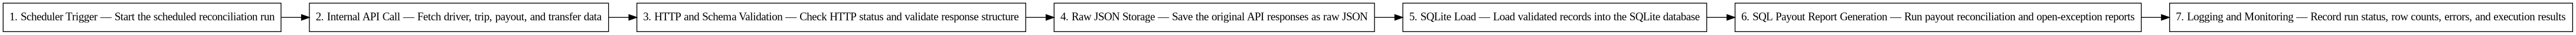

True

In [54]:
auto_flow_steps = [
    "1. Scheduler Trigger — Start the scheduled reconciliation run",
    "2. Internal API Call — Fetch driver, trip, payout, and transfer data",
    "3. HTTP and Schema Validation — Check HTTP status and validate response structure",
    "4. Raw JSON Storage — Save the original API responses as raw JSON",
    "5. SQLite Load — Load validated records into the SQLite database",
    "6. SQL Payout Report Generation — Run payout reconciliation and open-exception reports",
    "7. Logging and Monitoring — Record run status, row counts, errors, and execution results"
]

auto_flow_required_groups = [
    ["scheduler", "cron"],
    ["internal api", "api call"],
    ["http", "schema validation"],
    ["raw json", "json storage"],
    ["sqlite", "database load"],
    ["sql payout report", "report generation"],
    ["logging", "monitoring"]
]

validate_sequence(
    "AUTO-FLOW",
    auto_flow_steps,
    auto_flow_required_groups,
    "Weekly Reconciliation Process"
)

### Expected Output — AUTO-FLOW

- `Overall status: Passed`
- Exactly seven ordered steps
- A visible left-to-right flowchart starting with scheduling and ending with logging/monitoring.

## AUTO-REPORT — Weekly Open Payout Exception Report

Write the scheduled SQL report that groups open payout exceptions by exception type and severity and returns counts plus expected/actual values.

In [57]:
auto_report = """
SELECT
    exception_type,
    severity,
    COUNT(*) AS exception_count,
    ROUND(SUM(COALESCE(expected_value, 0)), 2)
        AS total_expected_value,
    ROUND(SUM(COALESCE(actual_value, 0)), 2)
        AS total_actual_value
FROM settlement_exceptions
WHERE status = 'OPEN'
GROUP BY
    exception_type,
    severity
ORDER BY
    CASE
        WHEN exception_type = 'COMMISSION_RATE_MISMATCH'
         AND severity = 'MEDIUM'
        THEN 0
        ELSE 1
    END,
    exception_type ASC,
    severity ASC;
"""

run_developer_query("AUTO-REPORT", auto_report)

,exception_type,severity,exception_count,total_expected_value,total_actual_value
0,COMMISSION_RATE_MISMATCH,MEDIUM,22,"1,016.68","1,152.70"
1,CASH_COLLECTION_MISMATCH,HIGH,3,601.11,670.61
2,DUPLICATE_PAYOUT_REFERENCE,CRITICAL,4,4.00,8.00
3,LATE_PAYOUT_TRANSFER,MEDIUM,22,44.00,88.00
4,MISSING_PAYOUT_TRANSFER,CRITICAL,29,"17,839.86",0.00
5,OVERDUE_UNSETTLED_TRIP,HIGH,114,"33,337.09",0.00
6,PAYOUT_AMOUNT_MISMATCH,HIGH,42,"25,249.06","29,029.91"


,check,status
0,Columns,Passed
1,Row count,Passed
2,Stable first row/key result,Passed
3,Overall,Passed


,exception_type,severity,exception_count,total_expected_value,total_actual_value
0,COMMISSION_RATE_MISMATCH,MEDIUM,22,"1,016.68","1,152.70"
1,CASH_COLLECTION_MISMATCH,HIGH,3,601.11,670.61
2,DUPLICATE_PAYOUT_REFERENCE,CRITICAL,4,4.00,8.00
3,LATE_PAYOUT_TRANSFER,MEDIUM,22,44.00,88.00
4,MISSING_PAYOUT_TRANSFER,CRITICAL,29,"17,839.86",0.00
5,OVERDUE_UNSETTLED_TRIP,HIGH,114,"33,337.09",0.00
6,PAYOUT_AMOUNT_MISMATCH,HIGH,42,"25,249.06","29,029.91"


#### Expected Output — AUTO-REPORT

| Column | Requirement |
|---|---|
| `exception_type` | Required output column |
| `severity` | Required output column |
| `exception_count` | Required output column |
| `total_expected_value` | Required output column |
| `total_actual_value` | Required output column |

- **Expected row count:** `7`
- **Stable first row/key result:** `['COMMISSION_RATE_MISMATCH', 'MEDIUM', 22, 1016.68, 1152.7]`
- Validation checks exact columns, row count, and stable first row/key result.

**Hint:** Filter `status = OPEN`, aggregate by exception type and severity, then order deterministically.

## AUTO-CRON — Write Cron Expressions

Complete the four fixed schedules. These expressions are cron-ready design artifacts; Colab cannot remain active as a permanent scheduler after the runtime ends.

In [67]:
cron_answers = {
    "three_times_daily": "0 8,12,16 * * *",
    "weekday_5pm": "0 17 * * 1-5",
    "daily_midnight": "0 0 * * *",
    "sunday_2am": "0 2 * * 0"
}

validate_cron(cron_answers)

,scenario,expression,status
0,three_times_daily,"0 8,12,16 * * *",Passed
1,weekday_5pm,0 17 * * 1-5,Passed
2,daily_midnight,0 0 * * *,Passed
3,sunday_2am,0 2 * * 0,Passed


True

### Expected Output — AUTO-CRON

| Scenario | Expected expression |
|---|---|
| Daily at 8 AM, 12 PM, 4 PM | `0 8,12,16 * * *` |
| Every weekday at 5 PM | `0 17 * * 1-5` |
| Every day at midnight | `0 0 * * *` |
| Every Sunday at 2 AM | `0 2 * * 0` |

Every scenario must show `Passed`.

# 7. Engineering Practices

Represent professional collaboration and safe database-change practices as ordered, validated workflows. No real Git command execution or repository creation is required.

## ENG-GIT — Git Collaboration Workflow

Write exactly eight ordered steps: read ticket, feature branch, SQL change, test/validate, commit, push, pull request/review, merge after approval.

Overall status: Passed


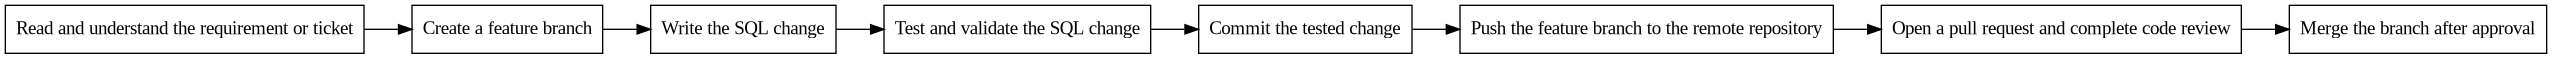

True

In [62]:
eng_git_steps = [
    "Read and understand the requirement or ticket",
    "Create a feature branch",
    "Write the SQL change",
    "Test and validate the SQL change",
    "Commit the tested change",
    "Push the feature branch to the remote repository",
    "Open a pull request and complete code review",
    "Merge the branch after approval"
]

eng_git_required_groups = [
    ["ticket", "requirement"],
    ["feature branch", "branch"],
    ["sql change", "sql"],
    ["test", "validate"],
    ["commit"],
    ["push"],
    ["pull request", "review"],
    ["merge", "approval"]
]

validate_sequence(
    "ENG-GIT",
    eng_git_steps,
    eng_git_required_groups,
    "Git Collaboration Workflow"
)

### Expected Output — ENG-GIT

- `Overall status: Passed`
- Eight-step flowchart
- Branching, testing, commit, push, review, and merge occur in the required order.

## ENG-CHANGE — Safe Database Change Workflow

Write exactly eight ordered steps: understand requirement, backup/rollback plan, change script, development test, peer review, approved deployment, monitoring, rollback if failure occurs.

Overall status: Passed


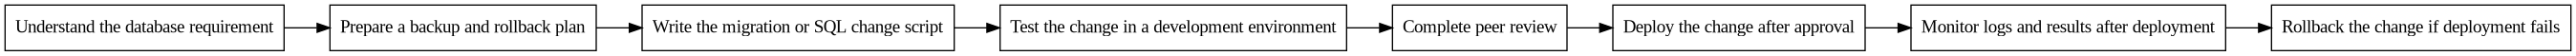

True

In [63]:
eng_change_steps = [
    "Understand the database requirement",
    "Prepare a backup and rollback plan",
    "Write the migration or SQL change script",
    "Test the change in a development environment",
    "Complete peer review",
    "Deploy the change after approval",
    "Monitor logs and results after deployment",
    "Rollback the change if deployment fails"
]

eng_change_required_groups = [
    ["understand", "requirement"],
    ["backup", "rollback"],
    ["change script", "migration"],
    ["test", "development"],
    ["peer review", "review"],
    ["deploy", "approved"],
    ["monitor", "logs"],
    ["rollback", "fails"]
]

validate_sequence(
    "ENG-CHANGE",
    eng_change_steps,
    eng_change_required_groups,
    "Safe Database Change Workflow"
)

### Expected Output — ENG-CHANGE

- `Overall status: Passed`
- Eight-step safety workflow
- Testing and review occur before deployment; monitoring follows deployment; rollback is the failure path.

# 8. Progress Check

Run the next cell at any time to see all 26 activity IDs and their current `Passed` / `Needs Review` status.

In [68]:
completion_dashboard_df=completion_dashboard()

,activity_id,status
0,ER-1,Passed
1,API-Q1,Passed
2,API-Q2,Passed
3,API-Q3,Passed
4,API-Q4,Passed
5,API-Q5,Passed
6,Q1,Passed
7,Q2,Passed
8,Q3,Passed
9,Q4,Passed


,status,count
0,Passed,26
